# UTS Data Acquisition & Management
## Bali Tourism Intelligence: Kunjungan Wisatawan Domestik Bulanan dan Cuaca (Rencana C)

**Alur:** Unduh → Catat (provenance) → Intip → Baca → Periksa/Bersihkan → Simpan → API → Scraping → Merge.

| Soal | Isi | Sel |
|---|---|---|
| 1 | Baca berkas (5 CSV statistik + Tabel 6, 7, 17, 28), identifikasi, estimasi storage | BAB 1–2 |
| 2 | Lisensi/ToS, PII, Data Ethics Checklist | BAB 3 |
| 3 | API (Open-Meteo, opsional BPS) | BAB 4 |
| 4 | robots.txt + scraping | BAB 5 |
| 5 | Merge + bukti tanpa duplikasi + simpan | BAB 6 |

**Dataset utama:** kunjungan wisatawan domestik bulanan ke Bali 2004–2025 (264 observasi) dari CSV Dinas Pariwisata Bali.
**Aturan:** raw data tidak pernah ditimpa; semua request memakai timeout, User-Agent berisi email kampus, dan jeda; API key tidak ditulis di notebook (pakai Colab Secrets).
**Cara pakai:** jalankan dari atas ke bawah. Isi bagian bertanda `# <-- ISI`.

## BAB 0. Persiapan lingkungan

In [ ]:
# ===== SEL 1: Pasang library yang belum ada (xlrd untuk membaca .xls) =====
import importlib, subprocess, sys

for modul, paket in [("xlrd", "xlrd")]:
    try:
        importlib.import_module(modul)          # sudah terpasang -> lewati
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paket], check=False)
print("Library siap.")

Library siap.


In [ ]:
# ===== SEL 2: Impor library, konfigurasi, dan pembuatan folder =====
import os, io, re, sys, json, time, hashlib
from datetime import datetime, timezone
from pathlib import Path
from urllib import robotparser

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# --- Konfigurasi yang HARUS diisi ---
EMAIL_KAMPUS = "mahasiswa@instiki.ac.id"          # <-- ISI: email kampus (masuk User-Agent)
NIM_FOLDER = "UTS_DATAAKUISISI_pariwisata_2501010376"        # nama folder proyek

# --- Lokasi proyek: Google Drive jika di Colab, folder lokal jika tidak ---
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive") / NIM_FOLDER
else:
    BASE_DIR = Path.cwd() / NIM_FOLDER

# --- Struktur folder ---
RAW_DIR = BASE_DIR / "data" / "raw"
BUKTI_DIR = RAW_DIR / "bukti_kepatuhan"       # robots.txt, halaman lisensi/ToS (bukti)
INTERIM_DIR = BASE_DIR / "data" / "interim"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
DOCS_DIR = BASE_DIR / "docs"
FIG_DIR = DOCS_DIR / "gambar"
for d in [RAW_DIR, BUKTI_DIR, INTERIM_DIR, PROCESSED_DIR, DOCS_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)      # aman: tidak menimpa isi folder

# --- Parameter etika request web ---
USER_AGENT = f"UTS-DAM-INSTIKI/1.0 (mahasiswa Informatika; {EMAIL_KAMPUS})"
TIMEOUT = (5, 30)        # (connect, read) dalam detik
JEDA_DETIK = 2           # jeda antar-request

# --- Sumber data (URL harus tepat karena masuk provenance) ---
URL_DISPARDA = "https://disparda.baliprov.go.id/buku-statistik-pariwisata-bali-tahun-2025"
URL_CSV_SUMBER = "https://bali.bps.go.id/id/statistics-table?subject=561"   # <-- ISI: URL portal/halaman unduhan CSV
LIS_DISPARDA = "Needs verification - lisensi khusus dataset belum ditemukan"
LIS_CSV = "Needs verification - cek ketentuan penggunaan portal sumber CSV; tidak diasumsikan CC BY"
CAT_DISPARDA = ("Statistik Pariwisata Bali 2025 (Dinas Pariwisata Prov. Bali); "
                "sumber asli tabel: BPS Provinsi Bali / Dinas Pariwisata (tertulis di tiap tabel)")

# --- Nama berkas CSV (harus SAMA dengan nama berkas yang kamu unggah) ---
CSV_WISNUS = "Banyaknya Wisatawan Domestik Bulanan ke Bali, 2004-2025.csv"
CSV_WISMAN_TAHUNAN = "Banyaknya Wisatawan Mancanegara ke Bali dan Indonesia, 1969-2025.csv"
CSV_PINTU = "Jumlah Wisatawan Mancanegara Bulanan ke Bali Menurut Pintu Masuk, 2025.csv"
CSV_TPK = "Tingkat Penghunian Kamar (TPK) Hotel Bintang Menurut Kelas di Provinsi Bali, 2025.csv"
CSV_KEBANGSAAN = "_Banyaknya Wisatawan Mancanegara yang Datang Langsung ke Bali Menurut Kebangsaan 2019-2024.csv"

# Daftar berkas mentah yang diharapkan: nama -> (url, lisensi, catatan)
# Excel: hanya workbook yang memuat Tabel 6, 7 (Table-1-7), 17 (Table-17), dan 28 (Table-24-31).
RAW_FILES = {
    "Table-1-7-Final-5.xls":   (URL_DISPARDA, LIS_DISPARDA, CAT_DISPARDA + " | memuat Tabel 6 dan 7"),
    "Table-17-Final-7.xlsx":   (URL_DISPARDA, LIS_DISPARDA, CAT_DISPARDA + " | memuat Tabel 17"),
    "Table-24-31-Final-5.xls": (URL_DISPARDA, LIS_DISPARDA, CAT_DISPARDA + " | memuat Tabel 28"),
    CSV_WISNUS:         (URL_CSV_SUMBER, LIS_CSV, "Wisatawan domestik bulanan ke Bali 2004-2025; sumber tertulis di berkas: Hasil Survei Dinas Pariwisata Provinsi Bali (DATASET UTAMA)"),
    CSV_WISMAN_TAHUNAN: (URL_CSV_SUMBER, LIS_CSV, "Wisman ke Indonesia dan Bali 1969-2025; sumber tertulis di berkas: BPS Provinsi Bali"),
    CSV_PINTU:          (URL_CSV_SUMBER, LIS_CSV, "Wisman bulanan menurut pintu masuk 2025; sumber: BPS Provinsi Bali (sesuai portal)"),
    CSV_TPK:            (URL_CSV_SUMBER, LIS_CSV, "TPK hotel bintang menurut kelas 2025 (bulanan); sumber: BPS Provinsi Bali (sesuai portal)"),
    CSV_KEBANGSAAN:     (URL_CSV_SUMBER, LIS_CSV, "Wisman langsung ke Bali menurut kebangsaan 2019-2024; sumber tertulis di berkas: BPS Provinsi Bali"),
}
print("Folder proyek :", BASE_DIR)
print("User-Agent    :", USER_AGENT)
print("Berkas mentah yang diharapkan:", len(RAW_FILES))

Mounted at /content/drive
Folder proyek : /content/drive/MyDrive/UTS_DATAAKUISISI_pariwisata_2501010376
User-Agent    : UTS-DAM-INSTIKI/1.0 (mahasiswa Informatika; mahasiswa@instiki.ac.id)
Berkas mentah yang diharapkan: 8


In [ ]:
# ===== SEL 3: Fungsi HTTP (timeout, retry, jeda, User-Agent) dan penyimpan raw =====
def sembunyikan(teks):
    # Samarkan API key pada URL/pesan error agar tidak bocor ke output notebook
    teks = re.sub(r"/key/[^/\s]+", "/key/***", str(teks))
    return re.sub(r"([?&](?:key|api_key|token)=)[^&\s]+", r"\1***", teks)

def buat_session():
    # Retry otomatis untuk status sementara (429/5xx) dengan backoff bertahap
    retry = Retry(total=3, backoff_factor=1.5, status_forcelist=[429, 500, 502, 503, 504],
                  allowed_methods=["GET"], respect_retry_after_header=True, raise_on_status=False)
    s = requests.Session()
    s.mount("https://", HTTPAdapter(max_retries=retry))
    s.mount("http://", HTTPAdapter(max_retries=retry))
    s.headers.update({"User-Agent": USER_AGENT})
    return s

SESSION = buat_session()

def http_get(url, **kwargs):
    # Satu-satunya pintu request web: wajib email kampus, timeout, dan jeda
    if "ISI_EMAIL" in EMAIL_KAMPUS:
        raise ValueError("Isi EMAIL_KAMPUS di SEL 2 terlebih dahulu.")
    time.sleep(JEDA_DETIK)
    resp = SESSION.get(url, timeout=TIMEOUT, **kwargs)
    print(f"GET {sembunyikan(resp.url)} -> status {resp.status_code}")
    resp.raise_for_status()                    # HTTPError bila 4xx/5xx
    return resp

def simpan_raw(nama, isi_bytes, folder=None):
    # Simpan byte apa adanya; file yang sudah ada TIDAK ditimpa (raw bersifat tetap)
    tujuan = (folder or RAW_DIR) / nama
    if tujuan.exists():
        print("SKIP (raw tidak ditimpa):", tujuan.name)
    else:
        tujuan.write_bytes(isi_bytes)
        print("Tersimpan:", tujuan.name)
    return tujuan
print("Fungsi HTTP siap.")

Fungsi HTTP siap.


In [ ]:
# ===== SEL 4: Fungsi provenance (URL, waktu akses UTC, lisensi, MD5) =====
PROV_PATH = DOCS_DIR / "provenance.json"

def utc_now():
    return datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S UTC")

def md5_file(path):
    # MD5 dihitung per blok agar aman untuk file besar
    h = hashlib.md5()
    with open(path, "rb") as f:
        for blok in iter(lambda: f.read(8192), b""):
            h.update(blok)
    return h.hexdigest()

def path_relatif(path):
    # Simpan path relatif terhadap folder proyek agar portabel (Colab/Drive/lokal)
    p = Path(path)
    if p.is_absolute() and "data" in p.parts:
        return str(Path(*p.parts[p.parts.index("data"):]))
    return str(p)

def muat_provenance():
    # Muat catatan lama (jika ada) dan samakan nama field lama dengan skema baru
    if not PROV_PATH.exists():
        return []
    data = json.loads(PROV_PATH.read_text(encoding="utf-8"))
    for e in data:
        if "waktu_pencatatan_utc" in e:
            e["waktu_akses_utc"] = e.pop("waktu_pencatatan_utc")
        e["file_lokal"] = path_relatif(e.get("file_lokal", ""))
    return data

PROVENANCE = muat_provenance()

def catat_provenance(nama, url, path, lisensi, metode, catatan="", waktu_akses=None):
    # Simpan/perbarui satu catatan. Jika file sama (MD5 sama), waktu akses pertama dipertahankan.
    global PROVENANCE
    md5_baru = md5_file(path)
    lama = next((e for e in PROVENANCE if e["nama_sumber"] == nama), None)
    if waktu_akses is None:
        waktu_akses = lama["waktu_akses_utc"] if lama and lama.get("md5") == md5_baru else utc_now()
    entri = {"nama_sumber": nama, "metode_akuisisi": metode, "url": sembunyikan(url),
             "waktu_akses_utc": waktu_akses, "lisensi": lisensi,
             "file_lokal": path_relatif(path), "ukuran_bytes": Path(path).stat().st_size,
             "md5": md5_baru, "sumber": catatan}
    PROVENANCE = [e for e in PROVENANCE if e["nama_sumber"] != nama] + [entri]
    PROV_PATH.write_text(json.dumps(PROVENANCE, indent=2, ensure_ascii=False), encoding="utf-8")
    return entri

print("Catatan provenance yang sudah ada:", len(PROVENANCE))

Catatan provenance yang sudah ada: 0


## BAB 1. Akuisisi (a): berkas mentah, provenance, dan intip

In [ ]:
# ===== SEL 5: Cek berkas mentah di data/raw; hanya unggah yang belum ada =====
ada = {nama: (RAW_DIR / nama).exists() for nama in RAW_FILES}
hilang = [n for n, v in ada.items() if not v]
print("Sudah ada :", [n for n, v in ada.items() if v])
print("Belum ada :", hilang)

if hilang:
    if IN_COLAB:
        from google.colab import files
        print("Unggah berkas yang belum ada (JANGAN unggah PDF soal ujian).")
        for nama, isi in files.upload().items():
            if nama in hilang:
                simpan_raw(nama, isi)
            else:
                print("DILEWATI (bukan berkas yang diharapkan / sudah ada):", nama)
    else:
        raise FileNotFoundError(f"Letakkan berkas ini di {RAW_DIR}: {hilang}")
else:
    print("Semua berkas mentah tersedia. Tidak ada yang perlu diunggah.")

Sudah ada : ['Banyaknya Wisatawan Domestik Bulanan ke Bali, 2004-2025.csv', 'Banyaknya Wisatawan Mancanegara ke Bali dan Indonesia, 1969-2025.csv', 'Jumlah Wisatawan Mancanegara Bulanan ke Bali Menurut Pintu Masuk, 2025.csv', 'Tingkat Penghunian Kamar (TPK) Hotel Bintang Menurut Kelas di Provinsi Bali, 2025.csv', '_Banyaknya Wisatawan Mancanegara yang Datang Langsung ke Bali Menurut Kebangsaan 2019-2024.csv']
Belum ada : ['Table-1-7-Final-5.xls', 'Table-17-Final-7.xlsx', 'Table-24-31-Final-5.xls']
Unggah berkas yang belum ada (JANGAN unggah PDF soal ujian).


Saving Table-1-7-Final-5.xls to Table-1-7-Final-5.xls
Saving Table-17-Final-7.xlsx to Table-17-Final-7.xlsx
Saving Table-24-31-Final-5.xls to Table-24-31-Final-5.xls
Tersimpan: Table-1-7-Final-5.xls
Tersimpan: Table-17-Final-7.xlsx
Tersimpan: Table-24-31-Final-5.xls


In [ ]:
# ===== SEL 6: Catat provenance semua berkas mentah =====
# Berkas diunduh manual. Waktu akses = waktu pencatatan pertama di notebook ini (bukan jam unduh asli),
# dan dipertahankan selama MD5 file tidak berubah.
for nama, (url, lisensi, catatan) in RAW_FILES.items():
    p = RAW_DIR / nama
    if p.exists():
        catat_provenance(nama, url, p, lisensi, "download manual", catatan)

df_prov = pd.DataFrame(PROVENANCE)
display(df_prov[["nama_sumber", "metode_akuisisi", "waktu_akses_utc", "ukuran_bytes", "md5"]])

,nama_sumber,metode_akuisisi,waktu_akses_utc,ukuran_bytes,md5
0,Table-1-7-Final-5.xls,download manual,2026-11-17 09:05:03 UTC,177152,95c90976c7f1eb4badb1a3a96c4a526b
1,Table-17-Final-7.xlsx,download manual,2026-11-17 09:05:03 UTC,63824,ce9d625286e52fd80a8c58558a08e1e2
2,Table-24-31-Final-5.xls,download manual,2026-11-17 09:05:03 UTC,129536,c670447a303c6bdb57fbaa12fa3e2189
3,"Banyaknya Wisatawan Domestik Bulanan ke Bali, ...",download manual,2026-11-17 09:05:03 UTC,3569,c0be2f368c6339e80ee7128a9ea6f55f
4,Banyaknya Wisatawan Mancanegara ke Bali dan In...,download manual,2026-11-17 09:05:03 UTC,3277,ab034ea9e86e16ae85766ee2b37f2af3
5,Jumlah Wisatawan Mancanegara Bulanan ke Bali M...,download manual,2026-11-17 09:05:03 UTC,520,c5ff482924d737e2538420433c6841cc
6,Tingkat Penghunian Kamar (TPK) Hotel Bintang M...,download manual,2026-11-17 09:05:03 UTC,761,daa7cd8e0c212f5d001118e9e37bf1a2
7,_Banyaknya Wisatawan Mancanegara yang Datang L...,download manual,2026-11-17 09:05:03 UTC,2964,de3d83169c1492b8b035c264e6a0a148


In [ ]:
# ===== SEL 7: Helper Excel/CSV + audit seluruh berkas (tahap "Intip") =====
def buka_excel(path):
    # Pilih engine dari isi file (ZIP = xlsx -> openpyxl, selain itu xls -> xlrd), bukan dari ekstensi
    with open(path, "rb") as f:
        magic = f.read(2)
    engine = "openpyxl" if magic == b"PK" else "xlrd"
    return pd.ExcelFile(path, engine=engine), engine

def baca_excel(path, **kwargs):
    # pd.read_excel dengan engine yang sesuai
    _, engine = buka_excel(path)
    return pd.read_excel(path, engine=engine, **kwargs)

def baca_csv_mentah(path):
    # Baca CSV apa adanya: semua sel berupa teks, tanpa menebak header.
    # utf-8-sig membuang BOM; names=range(20) menyamakan jumlah kolom antarbaris (CSV statistik tidak rapi).
    return pd.read_csv(path, header=None, dtype=str, encoding="utf-8-sig", skip_blank_lines=False,
                       keep_default_na=False, na_values=[""], names=range(20))

# --- Audit sheet Excel ---
baris = []
for f in sorted(RAW_DIR.glob("*.xls*")):
    xls, engine = buka_excel(f)
    for sh in xls.sheet_names:
        d = xls.parse(sh, header=None).dropna(how="all").dropna(axis=1, how="all")
        judul = ""
        for v in d.head(8).stack().tolist():           # teks pertama = tebakan judul tabel
            if isinstance(v, str) and v.strip():
                judul = v.strip().replace("\n", " ")[:90]
                break
        m = re.search(r"(\d+)(?:\s*-\s*(\d+))?", sh)
        baris.append({"file": f.name, "sheet": sh, "nomor_tabel": m.group(0) if m else "",
                      "baris": d.shape[0], "kolom": d.shape[1], "judul_tebakan": judul})

df_audit = pd.DataFrame(baris)
df_audit.to_csv(INTERIM_DIR / "audit_seluruh_sheet.csv", index=False, encoding="utf-8-sig")
print("Total sheet Excel:", len(df_audit), "| engine .xls memakai xlrd, .xlsx memakai openpyxl")
display(df_audit)

# --- Audit berkas CSV ---
baris_csv = []
for f in sorted(RAW_DIR.glob("*.csv")):
    d = baca_csv_mentah(f).dropna(how="all").dropna(axis=1, how="all")
    judul = next((str(v).strip()[:90] for v in d.head(3).stack().tolist() if str(v).strip()), "")
    baris_csv.append({"file": f.name, "ukuran_bytes": f.stat().st_size, "baris_tidak_kosong": d.shape[0],
                      "kolom_terisi": d.shape[1], "judul_tebakan": judul})
df_audit_csv = pd.DataFrame(baris_csv)
df_audit_csv.to_csv(INTERIM_DIR / "audit_seluruh_csv.csv", index=False, encoding="utf-8-sig")
print("\nTotal berkas CSV:", len(df_audit_csv))
display(df_audit_csv)

Total sheet Excel: 16 | engine .xls memakai xlrd, .xlsx memakai openpyxl


,file,sheet,nomor_tabel,baris,kolom,judul_tebakan
0,Table-1-7-Final-5.xls,tab1ok,1,112,6,TABLE 1.
1,Table-1-7-Final-5.xls,tab2_ok,2,70,7,DIRECT FOREIGN TOURIST ARRIVALS TO INDONESIA A...
2,Table-1-7-Final-5.xls,tab3ok,3,66,7,TABLE 3.
3,Table-1-7-Final-5.xls,tab4 ok,4,21,10,DIRECT FOREIGN TOURIST ARRIVALS TO BALI BY MONTH
4,Table-1-7-Final-5.xls,tab5ok,5,54,11,TABLE 5.
5,Table-1-7-Final-5.xls,tab6ok,6,32,8,DIRECT FOREIGN TOURIST ARRIVALS TO BALI BY MARKET
6,Table-1-7-Final-5.xls,tab7ok,7,201,17,DIRECT FOREIGN TOURIST ARRIVALS TO BALI BY NAT...
7,Table-17-Final-7.xlsx,Table 17,17,317,20,THE GROWTH OF FOREIGN TOURIST VISIT TO PLACE OF
8,Table-24-31-Final-5.xls,TAB 24ok,24,17,16,TABLE 24.
9,Table-24-31-Final-5.xls,TAB 25ok,25,15,11,TABLE 25.



Total berkas CSV: 5


,file,ukuran_bytes,baris_tidak_kosong,kolom_terisi,judul_tebakan
0,"Banyaknya Wisatawan Domestik Bulanan ke Bali, ...",3569,49,10,Kunjungan Wisatawan Domestik ke Bali per Bulan...
1,Banyaknya Wisatawan Mancanegara ke Bali dan In...,3277,34,10,"Jumlah Wisatawan Asing ke Indonesia dan Bali, ..."
2,Jumlah Wisatawan Mancanegara Bulanan ke Bali M...,520,7,14,Pintu Masuk Wisman
3,Tingkat Penghunian Kamar (TPK) Hotel Bintang M...,761,10,14,Kelas Hotel Bintang
4,_Banyaknya Wisatawan Mancanegara yang Datang L...,2964,39,9,Banyaknya Wisatawan Mancanegara yang Datang La...


In [ ]:
# ===== SEL 8: Intip mentah CSV dataset utama (wisatawan domestik bulanan) =====
PATH_WISNUS = RAW_DIR / CSV_WISNUS

# 1) Teks apa adanya: perhatikan BOM, pemisah ribuan berupa spasi, dan struktur blok tahun
teks_mentah = PATH_WISNUS.read_text(encoding="utf-8-sig").splitlines()
print("Jumlah baris teks :", len(teks_mentah))
print("Contoh 6 baris pertama:")
for t in teks_mentah[:6]:
    print("  ", repr(t))

# 2) Sebagai tabel mentah (header=None): lihat apa adanya, tanpa menebak header
raw_wisnus = baca_csv_mentah(PATH_WISNUS).dropna(how="all").dropna(axis=1, how="all")
print("\nUkuran tabel mentah (baris, kolom):", raw_wisnus.shape)
display(raw_wisnus.head(20))
print("Temuan intip: (1) judul dua bahasa di atas; (2) data terbagi 3 blok tahun (2004-2012, 2013-2021, 2022-2030);")
print("(3) angka memakai spasi sebagai pemisah ribuan; (4) ada baris BALI (total) dan Pertumbuhan;")
print("(5) tahun 2026-2030 kolomnya kosong; (6) '-' berarti tidak ada pembanding/data.")

Jumlah baris teks : 53
Contoh 6 baris pertama:
   '"Kunjungan Wisatawan Domestik ke Bali per Bulan, 2004-2025",,,,,,,,,'
   '"Number of Domestic Visitor to Bali by Month, 2004-2025",,,,,,,,,'
   ',,,,,,,,,'
   'Bulan,2004,2005,2006,2007,2008,2009,2010,2011,2012'
   'Januari, 167 106, 174 515, 202 857, 181 266, 225 955, 264 915, 349 575, 280 588, 333 199'
   'Pebruari, 133 660, 161 808, 161 413, 144 425, 190 792, 204 419, 238 789, 340 508, 305 934'

Ukuran tabel mentah (baris, kolom): (49, 10)


,0,1,2,3,4,5,6,7,8,9
0,Kunjungan Wisatawan Domestik ke Bali per Bulan...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"Number of Domestic Visitor to Bali by Month, 2...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Bulan,2004,2005,2006,2007,2008,2009,2010,2011,2012
4,Januari,167 106,174 515,202 857,181 266,225 955,264 915,349 575,280 588,333 199
5,Pebruari,133 660,161 808,161 413,144 425,190 792,204 419,238 789,340 508,305 934
6,Maret,118 369,194 411,171 795,161 009,221 181,255 203,202 995,358 313,307 616
7,April,129 730,174 033,192 182,165 509,206 631,247 100,396 898,385 228,331 378
8,Mei,142 186,190 855,188 152,183 736,226 339,289 635,421 369,463 452,525 076
9,Juni,167 718,201 990,204 284,214 957,256 448,304 213,455 456,568 264,569 635
10,Juli,212 463,254 264,245 909,244 032,329 362,340 610,489 307,573 103,524 334


Temuan intip: (1) judul dua bahasa di atas; (2) data terbagi 3 blok tahun (2004-2012, 2013-2021, 2022-2030);
(3) angka memakai spasi sebagai pemisah ribuan; (4) ada baris BALI (total) dan Pertumbuhan;
(5) tahun 2026-2030 kolomnya kosong; (6) '-' berarti tidak ada pembanding/data.


## BAB 2. Soal 1: baca, bersihkan, validasi, simpan, identifikasi

In [ ]:
# ===== SEL 9: Deteksi posisi header, lalu baca dengan parameter eksplisit =====
def angka(x):
    # Ubah sel teks menjadi angka: spasi (termasuk NBSP) = pemisah ribuan, '-' / kosong = NaN
    if x is None or (not isinstance(x, str) and pd.isna(x)):
        return np.nan
    s = re.sub(r"[\s\u00a0\u202f]", "", str(x))
    if s in ("", "-", "–", "—", ":"):
        return np.nan
    try:
        return float(s)
    except ValueError:
        return np.nan

def teks(v):
    # Sel -> teks bersih ('' bila kosong); bilangan bulat dari .xls (mis. 1.0) dijadikan '1'
    if v is None or (not isinstance(v, str) and pd.isna(v)):
        return ""
    if isinstance(v, (float, np.floating)) and float(v).is_integer():
        return str(int(v))
    return re.sub(r"\s+", " ", str(v)).strip()

MAP_BULAN = {"januari": 1, "februari": 2, "pebruari": 2, "maret": 3, "april": 4, "mei": 5, "juni": 6,
             "juli": 7, "agustus": 8, "september": 9, "oktober": 10, "nopember": 11, "november": 11,
             "desember": 12}

raw = baca_csv_mentah(PATH_WISNUS)
# Setiap blok tahun diawali baris yang kolom pertamanya "Bulan"
baris_hdr = raw.index[raw[0].astype(str).str.strip().str.lower() == "bulan"].tolist()
print("Baris header 'Bulan' (awal tiap blok tahun):", baris_hdr)
print("Parameter baca: encoding='utf-8-sig', header=None, dtype=str, skip_blank_lines=False;")
print("angka dibersihkan oleh angka() (spasi = pemisah ribuan, '-' = kosong).")
assert len(baris_hdr) >= 1, "Header 'Bulan' tidak ditemukan - periksa berkas CSV."
display(raw.loc[baris_hdr[0]: baris_hdr[0] + 14].dropna(axis=1, how="all"))

Baris header 'Bulan' (awal tiap blok tahun): [3, 19, 35]
Parameter baca: encoding='utf-8-sig', header=None, dtype=str, skip_blank_lines=False;
angka dibersihkan oleh angka() (spasi = pemisah ribuan, '-' = kosong).


,0,1,2,3,4,5,6,7,8,9
3,Bulan,2004,2005,2006,2007,2008,2009,2010,2011,2012
4,Januari,167 106,174 515,202 857,181 266,225 955,264 915,349 575,280 588,333 199
5,Pebruari,133 660,161 808,161 413,144 425,190 792,204 419,238 789,340 508,305 934
6,Maret,118 369,194 411,171 795,161 009,221 181,255 203,202 995,358 313,307 616
7,April,129 730,174 033,192 182,165 509,206 631,247 100,396 898,385 228,331 378
8,Mei,142 186,190 855,188 152,183 736,226 339,289 635,421 369,463 452,525 076
9,Juni,167 718,201 990,204 284,214 957,256 448,304 213,455 456,568 264,569 635
10,Juli,212 463,254 264,245 909,244 032,329 362,340 610,489 307,573 103,524 334
11,Agustus,171 034,217 782,218 117,217 822,259 511,280 972,377 570,440 751,661 334
12,September,168 420,218 382,196 167,181 846,205 304,352 257,594 662,609 633,572 359


In [ ]:
# ===== SEL 10: Bersihkan -> format panjang (tahun, bulan, kunjungan) =====
rows, total_sheet, growth_sheet = [], {}, {}
for h in baris_hdr:
    # kolom -> tahun untuk blok ini (kolom tahun kosong akan menghasilkan NaN dan dibuang nanti)
    tahun_kolom = {j: int(t) for j, t in enumerate(raw.loc[h, 1:].map(angka), start=1) if not np.isnan(t)}
    for _, r in raw.loc[h + 1: h + 14].iterrows():            # 12 bulan + baris BALI + baris Pertumbuhan
        lab = str(r[0]).strip().lower()
        for j, t in tahun_kolom.items():
            v = angka(r[j])
            if lab in MAP_BULAN:
                rows.append((t, MAP_BULAN[lab], v))
            elif lab == "bali":
                total_sheet[t] = v
            elif lab == "pertumbuhan":
                growth_sheet[t] = v

df_semua = pd.DataFrame(rows, columns=["tahun", "bulan", "kunjungan"])
ada_data = df_semua.groupby("tahun")["kunjungan"].apply(lambda s: s.notna().any())
tahun_valid = ada_data[ada_data].index                        # membuang 2026-2030 (kolom kosong)
print("Tahun dibuang karena kolom kosong:", sorted(set(df_semua["tahun"]) - set(tahun_valid)))

df_wisnus = df_semua[df_semua["tahun"].isin(tahun_valid)].copy()
df_wisnus["kunjungan"] = df_wisnus["kunjungan"].astype(int)
df_wisnus = df_wisnus.sort_values(["tahun", "bulan"]).reset_index(drop=True)

# Pemeriksaan 1: struktur
assert len(df_wisnus) == 12 * len(tahun_valid), f"Harapan {12*len(tahun_valid)} baris, didapat {len(df_wisnus)}"
assert len(df_wisnus) >= 100, "Syarat soal: dataset utama minimal 100 baris"
assert not df_wisnus.duplicated(["tahun", "bulan"]).any(), "Ada duplikasi (tahun, bulan)"
assert df_wisnus.isna().sum().sum() == 0, "Ada nilai kosong"
print("Struktur OK:", df_wisnus.shape, "| tahun", int(df_wisnus.tahun.min()), "-", int(df_wisnus.tahun.max()),
      "| missing:", int(df_wisnus.isna().sum().sum()))
display(df_wisnus.head(14))

Tahun dibuang karena kolom kosong: [2026, 2027, 2028, 2029, 2030]
Struktur OK: (264, 3) | tahun 2004 - 2025 | missing: 0


,tahun,bulan,kunjungan
0,2004,1,167106
1,2004,2,133660
2,2004,3,118369
3,2004,4,129730
4,2004,5,142186
5,2004,6,167718
6,2004,7,212463
7,2004,8,171034
8,2004,9,168420
9,2004,10,150827


In [ ]:
# ===== SEL 11: Validasi terhadap baris BALI (total) dan Pertumbuhan di berkas =====
total_xl = pd.Series(total_sheet).sort_index()
growth_xl = pd.Series(growth_sheet).sort_index()             # '-' sudah menjadi NaN

total_hit = df_wisnus.groupby("tahun")["kunjungan"].sum()
growth_hit = total_hit.pct_change() * 100                    # persen; tahun pertama tidak punya pembanding

cek_total = pd.DataFrame({"jumlah_12_bulan": total_hit, "total_di_sheet": total_xl.reindex(total_hit.index),
                          "growth_hitung": growth_hit.round(2),
                          "growth_di_sheet": growth_xl.reindex(total_hit.index)})
cek_total["total_sesuai"] = cek_total["jumlah_12_bulan"] == cek_total["total_di_sheet"]
# berkas membulatkan growth ke 2 desimal -> toleransi 0,006
cek_total["growth_sesuai"] = np.isclose(cek_total["growth_hitung"], cek_total["growth_di_sheet"], atol=0.006)
cek_total["growth_sesuai"] = cek_total["growth_sesuai"].astype(object)
tahun_pertama = cek_total.index.min()
cek_total.loc[tahun_pertama, "growth_sesuai"] = None         # tahun pertama tidak bisa dicek
display(cek_total)

assert cek_total["total_sesuai"].all(), "Ada tahun yang jumlahnya tidak cocok dengan baris BALI"
assert cek_total.loc[tahun_pertama + 1:, "growth_sesuai"].astype(bool).all(), "Ada growth rate yang tidak cocok"
print("Validasi lulus: jumlah 12 bulan = total BALI dan growth konsisten untuk semua tahun.")

,jumlah_12_bulan,total_di_sheet,growth_hitung,growth_di_sheet,total_sesuai,growth_sesuai
tahun,,,,,,
2004,2038186,2038186.0,NaN,NaN,True,None
2005,2408509,2408509.0,18.17,18.17,True,True
2006,2474787,2474787.0,2.75,2.75,True,True
2007,2484644,2484644.0,0.40,0.40,True,True
2008,2898793,2898793.0,16.67,16.67,True,True
2009,3521135,3521135.0,21.47,21.47,True,True
2010,4646343,4646343.0,31.96,31.96,True,True
2011,5675121,5675121.0,22.14,22.14,True,True
2012,6063558,6063558.0,6.84,6.84,True,True


Validasi lulus: jumlah 12 bulan = total BALI dan growth konsisten untuk semua tahun.


In [ ]:
# ===== SEL 12: Baca dan validasi 4 CSV pendukung (wisman tahunan, pintu masuk, TPK, kebangsaan) =====
# --- (a) Wisman ke Indonesia & Bali, tahunan 1969-2025 (dua panel tabel berdampingan) ---
raw_ta = baca_csv_mentah(RAW_DIR / CSV_WISMAN_TAHUNAN)
NAMA_KOL_TA = ["tahun", "wisman_indonesia", "growth_indonesia_persen", "wisman_bali", "growth_bali_persen"]
panel = []
for kolom in ([0, 1, 2, 3, 4], [6, 7, 8, 9, 10]):            # panel kiri 1969-1997, panel kanan 1998-2025
    p = raw_ta[kolom].copy()
    p.columns = NAMA_KOL_TA
    p = p[p["tahun"].astype(str).str.strip().str.fullmatch(r"\d{4}")]    # buang baris judul "Tahun/Year"
    panel.append(p)
df_wisman_tahunan = pd.concat(panel, ignore_index=True)
for c in NAMA_KOL_TA:
    df_wisman_tahunan[c] = df_wisman_tahunan[c].map(angka)
df_wisman_tahunan["tahun"] = df_wisman_tahunan["tahun"].astype(int)
df_wisman_tahunan = df_wisman_tahunan.sort_values("tahun").reset_index(drop=True)

assert df_wisman_tahunan["tahun"].is_unique and (df_wisman_tahunan["tahun"].diff().dropna() == 1).all(), "Tahun tidak berurutan"
g_hit = (df_wisman_tahunan["wisman_bali"].pct_change() * 100).round(2)
ada = df_wisman_tahunan["growth_bali_persen"].notna() & g_hit.notna()
selisih_g = (g_hit[ada] - df_wisman_tahunan.loc[ada, "growth_bali_persen"]).abs()
print(f"(a) Wisman tahunan: {df_wisman_tahunan.shape} | {df_wisman_tahunan.tahun.min()}-{df_wisman_tahunan.tahun.max()}"
      f" | growth Bali dicek {int(ada.sum())} tahun, selisih > 0,01: {int((selisih_g > 0.011).sum())}")
print("    Growth Bali kosong ('-') pada tahun:", df_wisman_tahunan.loc[df_wisman_tahunan.growth_bali_persen.isna(), "tahun"].tolist())
display(df_wisman_tahunan.tail(8))

# --- (b) Wisman bulanan menurut pintu masuk 2025 ---
raw_pm = baca_csv_mentah(RAW_DIR / CSV_PINTU)
tahun_pm = int(next(angka(v) for v in raw_pm[1] if isinstance(v, str) and re.fullmatch(r"\d{4}", v.strip())))
hdr_pm = raw_pm.index[raw_pm[1].astype(str).str.strip().str.lower() == "januari"][0]
bulan_kol = {j: MAP_BULAN[str(raw_pm.loc[hdr_pm, j]).strip().lower()] for j in range(1, 13)}
rows_pm, tahunan_pm = [], {}
for _, r in raw_pm.loc[hdr_pm + 1:].dropna(subset=[0]).iterrows():
    pintu = str(r[0]).strip()
    tahunan_pm[pintu] = angka(r[13])                          # kolom "Tahunan"
    for j, b in bulan_kol.items():
        rows_pm.append((pintu, tahun_pm, b, angka(r[j])))
df_pm_all = pd.DataFrame(rows_pm, columns=["pintu_masuk", "tahun", "bulan", "kunjungan"])
is_jumlah = df_pm_all["pintu_masuk"].str.lower() == "jumlah"
df_wisman_pintu = df_pm_all[~is_jumlah].reset_index(drop=True)             # 2 pintu x 12 bulan
jumlah_pm = df_pm_all[is_jumlah].set_index("bulan")["kunjungan"]

assert df_wisman_pintu["kunjungan"].notna().all()
# Bandingkan jumlah per pintu dengan baris Jumlah (per bulan) dan kolom Tahunan (per pintu).
cek_pintu_bulan = pd.DataFrame({"jumlah_semua_pintu": df_wisman_pintu.groupby("bulan")["kunjungan"].sum(),
                                "baris_jumlah_di_berkas": jumlah_pm})
cek_pintu_bulan["selisih"] = cek_pintu_bulan["baris_jumlah_di_berkas"] - cek_pintu_bulan["jumlah_semua_pintu"]
cek_pintu_tahun = pd.DataFrame({"jumlah_12_bulan": df_wisman_pintu.groupby("pintu_masuk")["kunjungan"].sum(),
                                "kolom_tahunan_di_berkas": pd.Series(tahunan_pm)}).dropna()
cek_pintu_tahun["selisih"] = cek_pintu_tahun["kolom_tahunan_di_berkas"] - cek_pintu_tahun["jumlah_12_bulan"]
# Yang HARUS konsisten: baris Jumlah itu sendiri (jumlah 12 bulan = kolom Tahunan baris Jumlah)
assert jumlah_pm.sum() == tahunan_pm["Jumlah"], "Baris Jumlah tidak konsisten dengan kolom Tahunan"
print(f"\n(b) Pintu masuk: {df_wisman_pintu.shape} | baris Jumlah: 12 bulan = Tahunan ({jumlah_pm.sum():,.0f})")
print("Bulan dengan selisih antara jumlah pintu dan baris Jumlah di berkas:")
display(cek_pintu_bulan[cek_pintu_bulan["selisih"] != 0])
print("Jumlah 12 bulan per pintu vs kolom Tahunan:")
display(cek_pintu_tahun)
print("Catatan: selisih ini berasal dari berkas sumber (nilai Bandara Juni kurang dari kolom Tahunan/baris Jumlah),")
print("dicatat apa adanya tanpa koreksi; baris Jumlah dikonfirmasi oleh Tabel 7 pada SEL TAMBAHAN D.")
cek_pintu_bulan.reset_index().to_csv(PROCESSED_DIR / "wisman_pintu_validasi_bulanan.csv", index=False, encoding="utf-8-sig")
display(df_wisman_pintu.head(6))

# --- (c) TPK hotel bintang menurut kelas, 2025 (bulanan) ---
raw_tpk = baca_csv_mentah(RAW_DIR / CSV_TPK)
tahun_tpk = int(next(angka(v) for v in raw_tpk[1] if isinstance(v, str) and re.fullmatch(r"\d{4}", v.strip())))
hdr_tpk = raw_tpk.index[raw_tpk[1].astype(str).str.strip().str.lower() == "januari"][0]
bulan_kol_tpk = {j: MAP_BULAN[str(raw_tpk.loc[hdr_tpk, j]).strip().lower()] for j in range(1, 13)}
rows_tpk, tahunan_tpk = [], {}
for _, r in raw_tpk.loc[hdr_tpk + 1:].dropna(subset=[0]).iterrows():
    kelas = str(r[0]).strip()
    tahunan_tpk[kelas] = angka(r[13])
    for j, b in bulan_kol_tpk.items():
        rows_tpk.append((kelas, tahun_tpk, b, angka(r[j])))
df_tpk = pd.DataFrame(rows_tpk, columns=["kelas_hotel", "tahun", "bulan", "tpk_persen"])

assert df_tpk["tpk_persen"].between(0, 100).all(), "TPK di luar 0-100 persen"
pivot = df_tpk.pivot(index="bulan", columns="kelas_hotel", values="tpk_persen")
kelas_bintang = [c for c in pivot.columns if c.lower() != "seluruh kelas"]
dalam_rentang = ((pivot["Seluruh Kelas"] >= pivot[kelas_bintang].min(axis=1) - 0.01) &
                 (pivot["Seluruh Kelas"] <= pivot[kelas_bintang].max(axis=1) + 0.01)).all()
print(f"\n(c) TPK: {df_tpk.shape} | semua nilai 0-100%: True | 'Seluruh Kelas' selalu di antara min-maks kelas bintang: {bool(dalam_rentang)}")
display(df_tpk.head(6))

# --- (d) Wisman langsung ke Bali menurut kebangsaan, 2019-2024 (hierarki kelompok -> negara) ---
raw_kb = baca_csv_mentah(RAW_DIR / CSV_KEBANGSAAN)
hdr_kb = raw_kb.index[raw_kb[0].astype(str).str.strip().str.lower().str.startswith("kebangsaan")][0]
tahun_kol_kb = {j: int(angka(raw_kb.loc[hdr_kb, j])) for j in range(3, 20) if not np.isnan(angka(raw_kb.loc[hdr_kb, j]))}
rows_kb, kelompok = [], None
for _, r in raw_kb.loc[hdr_kb + 1:].iterrows():
    c0, c1, c2 = teks(r[0]), teks(r[1]), teks(r[2])
    if c0.lower().startswith(("sumber", "source")):
        break                                                  # catatan sumber di bawah tabel
    if re.fullmatch(r"[IVX]+\.", c0):                          # baris kelompok: I. ASEAN, II. ASIA, ...
        kelompok, jenis, negara = c1, "subtotal_kelompok", "(subtotal kelompok)"
    elif re.fullmatch(r"\d+\.", c1):                           # baris negara: 1. Malaysia, ...
        jenis, negara = "negara", c2
    elif c1.lower().startswith("jumlah"):
        kelompok, jenis, negara = "TOTAL", "total", "Jumlah / Total"
    else:
        continue                                               # baris pertumbuhan/judul tidak dipakai di sini
    for j, t in tahun_kol_kb.items():
        rows_kb.append((kelompok, negara, jenis, t, angka(r[j])))
df_kebangsaan = pd.DataFrame(rows_kb, columns=["kelompok", "negara", "jenis_baris", "tahun", "kunjungan"])

# Validasi: jumlah negara per kelompok vs subtotal kelompok; jumlah subtotal vs total
sub = df_kebangsaan[df_kebangsaan.jenis_baris == "subtotal_kelompok"].set_index(["kelompok", "tahun"])["kunjungan"]
neg = df_kebangsaan[df_kebangsaan.jenis_baris == "negara"].groupby(["kelompok", "tahun"])["kunjungan"].agg(["sum", lambda s: int(s.isna().sum())])
neg.columns = ["jumlah_negara", "negara_kosong"]
cek_kb = pd.concat([sub.rename("subtotal_di_berkas"), neg], axis=1).dropna(subset=["subtotal_di_berkas"])
cek_kb = cek_kb[cek_kb["subtotal_di_berkas"].notna()].reset_index()
cek_kb["selisih"] = cek_kb["subtotal_di_berkas"] - cek_kb["jumlah_negara"]
cek_kb["status"] = np.select([cek_kb["negara_kosong"] > 0, cek_kb["selisih"] != 0],
                             ["ADA NEGARA KOSONG", "SELISIH"], "SESUAI")
total_kb = df_kebangsaan[df_kebangsaan.jenis_baris == "total"].set_index("tahun")["kunjungan"]
jml_sub = df_kebangsaan[df_kebangsaan.jenis_baris == "subtotal_kelompok"].groupby("tahun")["kunjungan"].sum()
cek_kb_total = pd.DataFrame({"jumlah_subtotal_kelompok": jml_sub, "total_di_berkas": total_kb})
cek_kb_total["sesuai"] = np.where(cek_kb_total["jumlah_subtotal_kelompok"] == 0, "TIDAK ADA RINCIAN KELOMPOK",
                                  np.where(cek_kb_total["jumlah_subtotal_kelompok"] == cek_kb_total["total_di_berkas"], "SESUAI", "SELISIH"))

print(f"\n(d) Kebangsaan: {df_kebangsaan.shape} | kelompok: {df_kebangsaan[df_kebangsaan.jenis_baris=='subtotal_kelompok'].kelompok.nunique()}"
      f" | negara: {df_kebangsaan[df_kebangsaan.jenis_baris=='negara'].negara.nunique()}")
print("Subtotal kelompok vs jumlah negara (hanya yang TIDAK sesuai/ada kosong; tahun 2021 seluruhnya '-'):")
display(cek_kb[cek_kb["status"] != "SESUAI"].query("tahun != 2021"))
print("Jumlah subtotal kelompok vs baris Total (2021: berkas hanya memuat total 51, rincian kelompok semuanya '-'):")
display(cek_kb_total)
print("Catatan: selisih/negara kosong ini berasal dari berkas sumber, dicatat apa adanya (tidak dikoreksi).")

(a) Wisman tahunan: (57, 5) | 1969-2025 | growth Bali dicek 54 tahun, selisih > 0,01: 0
    Growth Bali kosong ('-') pada tahun: [1969, 2021, 2022]


,tahun,wisman_indonesia,growth_indonesia_persen,wisman_bali,growth_bali_persen
49,2018,15806191.0,12.58,6070473.0,6.54
50,2019,16106954.0,1.88,6275210.0,3.37
51,2020,4052923.0,-74.84,1069473.0,-82.96
52,2021,1557530.0,-61.57,51.0,NaN
53,2022,5889031.0,278.10,2155747.0,NaN
54,2023,11677825.0,98.30,5273258.0,144.61
55,2024,13902420.0,19.05,6333360.0,20.10
56,2025,15386646.0,10.80,6948754.0,9.72



(b) Pintu masuk: (24, 4) | baris Jumlah: 12 bulan = Tahunan (6,948,754)
Bulan dengan selisih antara jumlah pintu dan baris Jumlah di berkas:


,jumlah_semua_pintu,baris_jumlah_di_berkas,selisih
bulan,,,
6,637568.0,637868.0,300.0


Jumlah 12 bulan per pintu vs kolom Tahunan:


,jumlah_12_bulan,kolom_tahunan_di_berkas,selisih
Bandara Ngurah Rai,6907285.0,6907585.0,300.0
Pelabuhan Laut,41169.0,41169.0,0.0


... (5 outputs left out)

,kelompok,tahun,subtotal_di_berkas,jumlah_negara,negara_kosong,selisih,status
5,ASIA (Tanpa Asean / Non Asean),2019,2321161.0,2331706.0,0.0,-10545.0,SELISIH
6,ASIA (Tanpa Asean / Non Asean),2020,334247.0,339481.0,0.0,-5234.0,SELISIH
7,ASIA (Tanpa Asean / Non Asean),2022,353456.0,357910.0,0.0,-4454.0,SELISIH
8,ASIA (Tanpa Asean / Non Asean),2023,1270111.0,840720.0,1.0,429391.0,ADA NEGARA KOSONG


Jumlah subtotal kelompok vs baris Total (2021: berkas hanya memuat total 51, rincian kelompok semuanya '-'):


,jumlah_subtotal_kelompok,total_di_berkas,sesuai
tahun,,,
2019,6275210.0,6275210.0,SESUAI
2020,1069473.0,1069473.0,SESUAI
2021,0.0,51.0,TIDAK ADA RINCIAN KELOMPOK
2022,2155747.0,2155747.0,SESUAI
2023,5273258.0,5273258.0,SESUAI
2024,6333360.0,6333360.0,SESUAI


Catatan: selisih/negara kosong ini berasal dari berkas sumber, dicatat apa adanya (tidak dikoreksi).


In [ ]:
# ===== SEL 13: Simpan hasil pembersihan (raw tidak disentuh) =====
hasil_simpan = {
    "wisnus_bulanan_2004_2025.csv": df_wisnus,
    "wisnus_validasi_total_growth.csv": cek_total.reset_index().rename(columns={"index": "tahun"}),
    "wisman_tahunan_1969_2025.csv": df_wisman_tahunan,
    "wisman_pintu_masuk_2025.csv": df_wisman_pintu,
    "tpk_hotel_bintang_2025.csv": df_tpk,
    "wisman_kebangsaan_2019_2024.csv": df_kebangsaan,
    "wisman_kebangsaan_validasi_kelompok.csv": cek_kb,
}
print("Tersimpan di data/processed:")
for nama, d in hasil_simpan.items():
    d.to_csv(PROCESSED_DIR / nama, index=False, encoding="utf-8-sig")
    print(" -", nama, f"({(PROCESSED_DIR / nama).stat().st_size:,} bytes, {len(d)} baris)")

Tersimpan di data/processed:
 - wisnus_bulanan_2004_2025.csv (3,795 bytes, 264 baris)
 - wisnus_validasi_total_growth.csv (1,063 bytes, 22 baris)
 - wisman_tahunan_1969_2025.csv (2,088 bytes, 57 baris)
 - wisman_pintu_masuk_2025.csv (802 bytes, 24 baris)
 - tpk_hotel_bintang_2025.csv (1,748 bytes, 72 baris)
 - wisman_kebangsaan_2019_2024.csv (10,977 bytes, 198 baris)
 - wisman_kebangsaan_validasi_kelompok.csv (1,587 bytes, 30 baris)


In [ ]:
# ===== SEL TAMBAHAN A: Pilih tabel yang akan diproses =====
# Dataset utama (CSV wisatawan domestik) sudah diproses khusus pada SEL 9-13.
# Tabel Excel yang diproses hanya: 6, 7 (Table-1-7), 17 (Table-17), 28 (Table-24-31).
TABEL_PILIHAN = ["6", "7", "17", "28"]

# Ambil kandidat sheet dari hasil audit SEL 7.
audit_pilihan = df_audit[df_audit["nomor_tabel"].astype(str).isin(TABEL_PILIHAN)].copy()

# Jika nomor tabel ditemukan pada lebih dari satu workbook, pilih satu sheet per nomor.
# Prioritas workbook khusus (misalnya file Table-17) jika nama filenya menyebut nomor tabel.
def skor_sumber_tabel(row, nomor):
    nama = str(row["file"]).lower()
    skor = 0
    if re.search(rf"table[-_ ]?{re.escape(nomor)}(?:[-_. ]|$)", nama):
        skor += 100
    if "final" in nama:
        skor += 5
    return skor

pilihan_sheet = []
for nomor in TABEL_PILIHAN:
    kandidat = audit_pilihan[audit_pilihan["nomor_tabel"].astype(str) == nomor].copy()
    if kandidat.empty:
        print(f"PERINGATAN: Tabel {nomor} tidak ditemukan di df_audit.")
        continue
    kandidat["_skor"] = kandidat.apply(lambda r: skor_sumber_tabel(r, nomor), axis=1)
    kandidat = kandidat.sort_values(["_skor", "baris"], ascending=[False, False])
    pilihan_sheet.append(kandidat.iloc[0].drop(labels=["_skor"]))

df_pemetaan_tabel = pd.DataFrame(pilihan_sheet).reset_index(drop=True)
assert len(df_pemetaan_tabel) == len(TABEL_PILIHAN), "Ada tabel pilihan yang tidak ditemukan - periksa berkas Excel di data/raw"
print("Pemetaan sheet tabel pilihan:")
display(df_pemetaan_tabel[["nomor_tabel", "file", "sheet", "baris", "kolom", "judul_tebakan"]])

Pemetaan sheet tabel pilihan:


,nomor_tabel,file,sheet,baris,kolom,judul_tebakan
0,6,Table-1-7-Final-5.xls,tab6ok,32,8,DIRECT FOREIGN TOURIST ARRIVALS TO BALI BY MARKET
1,7,Table-1-7-Final-5.xls,tab7ok,201,17,DIRECT FOREIGN TOURIST ARRIVALS TO BALI BY NAT...
2,17,Table-17-Final-7.xlsx,Table 17,317,20,THE GROWTH OF FOREIGN TOURIST VISIT TO PLACE OF
3,28,Table-24-31-Final-5.xls,TAB 28ok,26,13,TABLE 28.


In [ ]:
# ===== SEL TAMBAHAN B: Baca dan bersihkan tabel pilihan (6, 7, 17, 28) =====
# Tiap tabel punya tata letak berbeda (header bertingkat, baris subtotal, catatan kaki), jadi dibaca dengan
# fungsi khusus per tabel dan tetap dalam bentuk lebar agar mirip sumbernya. Fungsi generik disediakan sebagai
# cadangan bila nanti tabel lain ditambahkan ke TABEL_PILIHAN.
NA_TABEL = ["-", "–", "—", "n.a", "NA", "N/A", ""]
BULAN_SINGKAT = ["jan", "feb", "mar", "apr", "mei", "jun", "jul", "agu", "sep", "okt", "nov", "des"]

def _berhenti(teks_sel):
    return teks_sel.upper().startswith(("SOURCE", "SUMBER"))

# ---------- Tabel 6: 20 negara pasar utama wisman, 2024 vs 2025 ----------
def parse_tabel_6(raw):
    kol0 = raw[0].astype(str).str.strip().str.upper()
    hdr = kol0[kol0 == "NATIONALITY"].index[0]
    data = raw.loc[hdr + 1:, raw.columns[:8]].copy()
    data.columns = ["negara", "peringkat_2024", "kunjungan_2024", "pangsa_2024_persen",
                    "peringkat_2025", "kunjungan_2025", "perubahan_persen", "pangsa_2025_persen"]
    data = data[data["negara"].notna()]
    stop = data["negara"].map(lambda v: _berhenti(teks(v))).to_numpy()
    if stop.any():
        data = data.iloc[:int(np.argmax(stop))]
    data["negara"] = data["negara"].map(teks)
    for c in ["peringkat_2024", "peringkat_2025"]:
        data[c] = data[c].map(teks).replace("", np.nan)         # peringkat = angka Romawi (teks)
    for c in ["kunjungan_2024", "pangsa_2024_persen", "kunjungan_2025", "perubahan_persen", "pangsa_2025_persen"]:
        data[c] = data[c].map(angka)
    nama = data["negara"].str.upper()
    data["jenis_baris"] = np.select([nama == "TOTAL", nama == "OTHER NATIONALITIES", nama == "TOTAL ARRIVAL"],
                                    ["subtotal_20_negara", "lainnya", "total_keseluruhan"], "negara")
    return data.reset_index(drop=True)

# ---------- Tabel 7: kedatangan wisman per kebangsaan per bulan 2025 ----------
def parse_tabel_7(raw):
    kol0 = raw[0].astype(str).str.strip().str.upper()
    kol1 = raw[1].astype(str).str.strip().str.upper()
    hdr = raw.index[(kol0 == "NO") & (kol1 == "NATIONALITY")][0]
    kolom_angka = BULAN_SINGKAT + ["total_tahunan", "persen_total"]
    data = raw.loc[hdr + 1:, raw.columns[:16]].copy()
    data.columns = ["no_urut", "negara"] + kolom_angka
    hasil, kelompok = [], None
    for _, r in data.iterrows():
        no, nama = teks(r["no_urut"]), teks(r["negara"])
        if not nama:
            continue                                            # catatan kaki / baris kosong
        nilai = [angka(r[c]) for c in kolom_angka]
        ada_nilai = not np.isnan(nilai[:13]).all()
        if re.fullmatch(r"[IVX]+", no):                         # baris kelompok benua/wilayah
            kelompok = nama
            if ada_nilai:                                       # ASEAN, AFRICA, dst. punya subtotal di baris yang sama
                hasil.append([kelompok, no, nama, "subtotal"] + nilai)
            continue
        if nama.upper() == "EXCLUDING ASEAN":                   # subtotal kelompok ASIA PACIFIC ada di baris ini
            hasil.append([kelompok, "", nama, "subtotal"] + nilai)
            continue
        if nama.upper() == "TOTAL":
            hasil.append(["TOTAL", "", nama, "total"] + nilai)
            break                                               # sisanya catatan kaki
        if ada_nilai:
            hasil.append([kelompok, no, nama, "negara"] + nilai)
    return pd.DataFrame(hasil, columns=["kelompok", "no_urut", "negara", "jenis_baris"] + kolom_angka)

# ---------- Tabel 17: kunjungan ke obyek & daya tarik wisata (ODTW) per kabupaten/kota ----------
def parse_tabel_17(raw):
    kol0 = raw[0].astype(str).str.strip().str.upper()
    hdr = kol0[kol0 == "NO."].index[0]
    # baris label 'wisnus/wisman' = baris pertama setelah header yang memuatnya
    sub_idx = next(i for i in range(hdr + 1, hdr + 8)
                   if raw.loc[i, 2:19].astype(str).str.lower().str.contains("wisnus").any())
    tahun = raw.loc[hdr, 2:19].map(angka).ffill()               # tahun hanya tertulis di kolom pertama tiap pasangan
    sub = raw.loc[sub_idx, 2:19].astype(str).str.strip().str.lower()
    sub = sub.where(sub.isin(["wisnus", "wisman"]), "total")    # 2016-2017 tidak dipisah wisnus/wisman
    nama_kol = [f"{int(t)}_{s}" for t, s in zip(tahun, sub)]
    hasil, kabupaten = [], None
    for i in range(sub_idx + 1, len(raw)):
        no, nama = teks(raw.loc[i, 0]), teks(raw.loc[i, 1])
        nilai = [angka(raw.loc[i, c]) for c in range(2, 20)]
        ada_nilai = not np.isnan(nilai).all()
        if nama.upper().startswith(("BALI GOVERNMENT", "DINAS PARIWISATA")) or _berhenti(no):
            break
        if re.fullmatch(r"[IVX]+", no) and nama:                # awal bagian kabupaten/kota
            kabupaten = nama
            continue
        if nama.upper() == "TOTAL":
            hasil.append(["SELURUH BALI", "", "TOTAL", "total_bali"] + nilai)
        elif nama.upper() == "JUMLAH":
            hasil.append([kabupaten, "", "JUMLAH", "subtotal_kabupaten"] + nilai)
        elif not nama and ada_nilai:                            # subtotal terakhir (Tabanan) tidak berlabel di sumber
            hasil.append([kabupaten, "", "JUMLAH (baris tanpa label di sumber)", "subtotal_kabupaten"] + nilai)
        elif nama and no:
            hasil.append([kabupaten, no, nama, "objek"] + nilai)
    return pd.DataFrame(hasil, columns=["kabupaten_kota", "no_urut", "objek_wisata", "jenis_baris"] + nama_kol)

# ---------- Tabel 28: perkembangan kepariwisataan Bali 2019-2025 ----------
def parse_tabel_28(raw):
    kol0 = raw[0].astype(str).str.strip().str.upper()
    hdr = kol0[kol0 == "NO"].index[0]
    tahun_kol = {j: int(angka(raw.loc[hdr, j])) for j in range(3, raw.shape[1]) if not np.isnan(angka(raw.loc[hdr, j]))}
    item, baris = None, []
    for i in range(hdr + 1, len(raw)):
        no, c2, c3, c5 = teks(raw.loc[i, 0]), teks(raw.loc[i, 2]), teks(raw.loc[i, 3]), teks(raw.loc[i, 5])
        nilai = [angka(raw.loc[i, j]) for j in tahun_kol]
        ada_nilai = not np.isnan(nilai).all()
        if _berhenti(no):
            break
        if no.isdigit():                                        # butir baru: 1, 2, 3, ...
            item = {"no": int(no), "uraian": c2, "sub": ""}
            if ada_nilai:
                baris.append((item, c5, nilai))
        elif re.fullmatch(r"[a-z]\.", c2) and item:             # sub-butir a., b., c.
            item = {"no": item["no"], "uraian": item["uraian"], "sub": c3}
            if ada_nilai:
                baris.append((item, c5, nilai))
        elif ada_nilai and item:                                # baris lanjutan satuan (Room / Seat)
            baris.append((item, c5, nilai))
        elif c2 and item:                                       # lanjutan teks uraian ("to Bali", "via ...")
            item["uraian"] = (item["uraian"] + " " + c2).strip()
    hasil = [[it["no"], it["uraian"], it["sub"], sat] + nil for it, sat, nil in baris]
    return pd.DataFrame(hasil, columns=["no_urut", "uraian", "sub_uraian", "satuan"] + [str(t) for t in tahun_kol.values()])

# ---------- Cadangan generik (dipakai hanya jika tabel tidak punya fungsi khusus) ----------
KATA_KUNCI_HEADER_TABEL = {"NO", "NO.", "MONTH", "BULAN", "YEAR", "TAHUN", "REGENCY/CITY", "REGENCY", "CITY",
                           "KABUPATEN", "KOTA", "REGION", "WILAYAH", "COUNTRY", "NEGARA", "OBJECT", "OBJEK",
                           "DESCRIPTION", "URAIAN", "TOURIST RESORT", "PLACES OF INTEREST"}

def parse_generik(raw):
    raw = raw.dropna(how="all").dropna(axis=1, how="all").reset_index(drop=True)
    kandidat = []
    for i in range(min(len(raw), 20)):
        vals = [str(v).strip().upper() for v in raw.iloc[i].tolist() if pd.notna(v)]
        kandidat.append((sum(v in KATA_KUNCI_HEADER_TABEL for v in vals), len(vals), i))
    baris_header = sorted(kandidat, key=lambda x: (x[0], x[1]), reverse=True)[0][2]
    nama = [re.sub(r"\s+", "_", str(v).strip().lower()) if pd.notna(v) else f"kolom_{j+1}"
            for j, v in enumerate(raw.iloc[baris_header].tolist())]
    data = raw.iloc[baris_header + 1:].copy()
    data.columns = nama
    return data.dropna(how="all").reset_index(drop=True)

PARSER_TABEL = {"6": parse_tabel_6, "7": parse_tabel_7, "17": parse_tabel_17, "28": parse_tabel_28}

tabel_terpilih_bersih, info_baca_tabel = {}, []
for _, r in df_pemetaan_tabel.iterrows():
    nomor, path, sheet = str(r["nomor_tabel"]), RAW_DIR / str(r["file"]), str(r["sheet"])
    try:
        raw_t = baca_excel(path, sheet_name=sheet, header=None).replace(NA_TABEL, np.nan)
        bersih = PARSER_TABEL.get(nomor, parse_generik)(raw_t)
        tabel_terpilih_bersih[nomor] = bersih
        info_baca_tabel.append({"nomor_tabel": nomor, "file": path.name, "sheet": sheet,
                                "baris_mentah": raw_t.shape[0], "baris_bersih": len(bersih),
                                "jumlah_kolom": len(bersih.columns),
                                "parser": PARSER_TABEL.get(nomor, parse_generik).__name__, "status_baca": "BERHASIL"})
        print(f"Tabel {nomor}: berhasil | {bersih.shape[0]} baris x {bersih.shape[1]} kolom")
        display(bersih.head(8))
    except Exception as e:
        info_baca_tabel.append({"nomor_tabel": nomor, "file": path.name, "sheet": sheet, "baris_mentah": None,
                                "baris_bersih": None, "jumlah_kolom": None, "parser": None,
                                "status_baca": f"GAGAL: {type(e).__name__}: {e}"})
        print(f"Tabel {nomor}: GAGAL dibaca -> {type(e).__name__}: {e}")

df_info_baca_tabel = pd.DataFrame(info_baca_tabel)
display(df_info_baca_tabel)

Tabel 6: berhasil | 23 baris x 9 kolom


,negara,peringkat_2024,kunjungan_2024,pangsa_2024_persen,peringkat_2025,kunjungan_2025,perubahan_persen,pangsa_2025_persen,jenis_baris
0,AUSTRALIAN,I,1544141.0,24.381071,I,1628459.0,5.460512,23.435266,negara
1,INDIAN,II,550379.0,8.690158,II,569261.0,3.430727,8.192274,negara
2,CHINESE,III,448446.0,7.080697,III,537375.0,19.830481,7.733401,negara
3,SOUTH KOREAN,VII,294024.0,4.642465,IV,346679.0,17.908402,4.989081,negara
4,BRITISH,IV,295326.0,4.663022,V,317523.0,7.516101,4.569495,negara
5,FRENCH,VII,257504.0,4.065836,VI,279117.0,8.393268,4.016792,negara
6,AMERICAN,V,261863.0,4.134662,VII,274611.0,4.868194,3.951946,negara
7,MALAYSIAN,VIII,246145.0,3.886484,VIII,251156.0,2.035792,3.614403,negara


Tabel 7: berhasil | 192 baris x 18 kolom


,kelompok,no_urut,negara,jenis_baris,jan,feb,mar,apr,mei,jun,jul,agu,sep,okt,nov,des,total_tahunan,persen_total
0,ASIA PACIFIC,,EXCLUDING ASEAN,subtotal,307053.0,242924.0,242180.0,308532.0,329882.0,349066.0,368385.0,350533.0,339880.0,324794.0,269820.0,316415.0,3749464.0,53.958796
1,ASIA PACIFIC,1,Australian,negara,134483.0,96421.0,103892.0,139481.0,138515.0,143915.0,161051.0,145756.0,152440.0,147581.0,123937.0,140987.0,1628459.0,23.435266
2,ASIA PACIFIC,2,Bhutan,negara,0.0,0.0,0.0,0.0,0.0,82.0,66.0,0.0,0.0,0.0,124.0,71.0,343.0,0.004936
3,ASIA PACIFIC,3,Bangladesh,negara,889.0,801.0,792.0,883.0,466.0,773.0,555.0,525.0,690.0,705.0,795.0,917.0,8791.0,0.126512
4,ASIA PACIFIC,4,Fiji,negara,0.0,0.0,86.0,0.0,167.0,99.0,77.0,0.0,122.0,142.0,132.0,139.0,964.0,0.013873
5,ASIA PACIFIC,5,Hongkong,negara,3181.0,2298.0,2763.0,5593.0,5582.0,7182.0,5914.0,5562.0,5287.0,5337.0,3384.0,4460.0,56543.0,0.813714
6,ASIA PACIFIC,6,India,negara,35158.0,38290.0,43790.0,49658.0,67995.0,65659.0,45288.0,39877.0,42424.0,41130.0,42729.0,57263.0,569261.0,8.192274
7,ASIA PACIFIC,7,Japan,negara,11420.0,15769.0,18322.0,11658.0,12608.0,15488.0,18038.0,30539.0,25175.0,18435.0,12710.0,18453.0,208615.0,3.002193


Tabel 17: berhasil | 300 baris x 22 kolom


/tmp/ipykernel_820/4166617287.py:144: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  raw_t = baca_excel(path, sheet_name=sheet, header=None).replace(NA_TABEL, np.nan)


,kabupaten_kota,no_urut,objek_wisata,jenis_baris,2016_total,2017_total,2018_wisnus,2018_wisman,2019_wisnus,2019_wisman,2020_wisnus,2020_wisman,2021_wisnus,2021_wisman,2022_wisnus,2022_wisman,2023_wisnus,2023_wisman,2024_wisnus,2024_wisman,2025_wisnus,2025_wisman
0,DENPASAR CITY,1,Museum Bali,objek,38437.0,31693.0,18927.0,16704.0,18815.0,13457.0,4248.0,3082.0,1991.0,86.0,11535.0,6553.0,18230.0,13803.0,24796.0,13835.0,11473.0,6898.0
1,DENPASAR CITY,2,Museum Le Mayuer,objek,6194.0,5229.0,1798.0,3324.0,1108.0,2476.0,1345.0,413.0,131.0,1.0,845.0,707.0,1984.0,1848.0,3816.0,1466.0,1295.0,855.0
2,DENPASAR CITY,3,Taman Budaya art centre,objek,14345.0,10300.0,5078.0,2286.0,6357.0,1196.0,717.0,93.0,1903.0,12.0,9895.0,439.0,3720.0,917.0,621.0,212.0,166.0,316.0
3,DENPASAR CITY,4,Pulau Serangan,objek,16303.0,28005.0,9799.0,28628.0,12568.0,35709.0,2395.0,2595.0,1404.0,214.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
4,DENPASAR CITY,5,Prasasti Blanjong,objek,313.0,211.0,121.0,133.0,NaN,NaN,0.0,0.0,73.0,0.0,42.0,14.0,8.0,6.0,69.0,10.0,NaN,NaN
5,DENPASAR CITY,6,Pasar Kumbasari,objek,11123.0,10464.0,NaN,7856.0,NaN,6035.0,0.0,1319.0,0.0,0.0,0.0,576.0,4775.0,2478.0,10162.0,7670.0,22012.0,18194.0
6,DENPASAR CITY,7,Pasar Badung,objek,4114.0,NaN,NaN,NaN,NaN,9836.0,0.0,2660.0,0.0,0.0,157.0,6769.0,18737.0,13924.0,19705.0,15058.0,21270.0,15791.0
7,DENPASAR CITY,8,Museum Lukisan Sidik Jari,objek,425.0,429.0,696.0,153.0,705.0,80.0,147.0,14.0,223.0,23.0,199.0,5.0,325.0,10.0,204.0,19.0,53.0,2.0


Tabel 28: berhasil | 16 baris x 11 kolom


,no_urut,uraian,sub_uraian,satuan,2019,2020,2021,2022,2023,2024,2025
0,1,Direct Foreign Tourist Arrival to Bali,,,6275210.0,1069473.0,51.0,2155747.0,5273258.0,6333360.0,6948754.0
1,2,Number of Passangers to Bali via Ngurah Rai Ai...,,,11312189.0,2918682.0,1882404.0,6343711.0,10659625.0,11884433.0,11961772.0
2,3,Number of Passangers to Bali via Gilimanuk Har...,,,5565837.0,2710790.0,3088999.0,5360063.0,6402915.0,7009472.0,7101964.0
3,4,Number of Passangers to Bali via Padang Bai Ha...,,,531949.0,333539.0,254057.0,346476.0,301482.0,514864.0,544477.0
4,5,Accomodation,,Unit,5373.0,5610.0,2698.0,3020.0,7573.0,6650.0,9509.0
5,5,Accomodation,,Room,87902.0,92708.0,102136.0,81947.0,68594.0,0.0,NaN
6,5,Accomodation,Hotel Bintang,Unit,265.0,266.0,406.0,319.0,435.0,1297.0,1694.0
7,5,Accomodation,Hotel Bintang,Room,35819.0,36319.0,58706.0,38427.0,35394.0,0.0,NaN


,nomor_tabel,file,sheet,baris_mentah,baris_bersih,jumlah_kolom,parser,status_baca
0,6,Table-1-7-Final-5.xls,tab6ok,34,23,9,parse_tabel_6,BERHASIL
1,7,Table-1-7-Final-5.xls,tab7ok,203,192,18,parse_tabel_7,BERHASIL
2,17,Table-17-Final-7.xlsx,Table 17,322,300,22,parse_tabel_17,BERHASIL
3,28,Table-24-31-Final-5.xls,TAB 28ok,29,16,11,parse_tabel_28,BERHASIL


In [ ]:
# ===== SEL TAMBAHAN C: Validasi dan simpan tabel pilihan =====
# Dua lapis: (1) validasi umum (struktur, missing, duplikat), (2) validasi khusus tiap tabel berdasarkan
# angka subtotal/total yang tertulis di sumber. Selisih di sumber DICATAT, bukan dikoreksi.
cek_khusus = []
def catat(nomor, pemeriksaan, lulus, detail=""):
    cek_khusus.append({"nomor_tabel": nomor, "pemeriksaan": pemeriksaan,
                       "hasil": "LULUS" if lulus else "PERLU DICATAT", "detail": detail})

def validasi_6(d):
    neg = d[d.jenis_baris == "negara"]
    sub = d[d.jenis_baris == "subtotal_20_negara"].iloc[0]
    lain = d[d.jenis_baris == "lainnya"].iloc[0]
    tot = d[d.jenis_baris == "total_keseluruhan"].iloc[0]
    for th in ["2024", "2025"]:
        k, p = f"kunjungan_{th}", f"pangsa_{th}_persen"
        catat("6", f"jumlah 20 negara = baris TOTAL ({th})", neg[k].sum() == sub[k], f"{neg[k].sum():,.0f} vs {sub[k]:,.0f}")
        catat("6", f"TOTAL + OTHER = TOTAL ARRIVAL ({th})", sub[k] + lain[k] == tot[k], f"{sub[k] + lain[k]:,.0f} vs {tot[k]:,.0f}")
        catat("6", f"pangsa 20 negara + lainnya = 100% ({th})", np.isclose(neg[p].sum() + lain[p], 100, atol=0.01), f"{neg[p].sum() + lain[p]:.4f}")
        ganda = int(neg[f"peringkat_{th}"].dropna().duplicated().sum())
        catat("6", f"peringkat {th} unik", ganda == 0, f"{ganda} peringkat ganda di sumber (peringkat dicatat apa adanya)")

def validasi_7(d):
    neg = d[d.jenis_baris == "negara"]
    kolom = BULAN_SINGKAT + ["total_tahunan"]
    selisih_baris = (neg[BULAN_SINGKAT].fillna(0).sum(axis=1) - neg["total_tahunan"]).abs()
    catat("7", "jumlah 12 bulan = kolom TOTAL (tiap negara)", int((selisih_baris > 0).sum()) == 0,
          f"{int((selisih_baris > 0).sum())} dari {len(neg)} negara tidak cocok")
    kosong = int(neg[BULAN_SINGKAT].isna().sum().sum())
    catat("7", "sel bulan kosong pada baris negara", kosong == 0, f"{kosong} sel kosong (dihitung 0 saat menjumlah)")
    tak_cocok = []
    for k in d[d.jenis_baris == "subtotal"]["kelompok"].unique():
        s = d[(d.jenis_baris == "subtotal") & (d.kelompok == k)][kolom].iloc[0]
        j = neg[neg.kelompok == k][kolom].fillna(0).sum()
        if k and (neg.kelompok == k).any() and not np.allclose(s.fillna(0), j):
            tak_cocok.append(k)
    catat("7", "jumlah negara = subtotal kelompok", not tak_cocok, "kelompok tidak cocok: " + (", ".join(tak_cocok) or "tidak ada"))
    tot = d[d.jenis_baris == "total"][kolom].iloc[0]
    jml = d[d.jenis_baris == "subtotal"][kolom].sum()
    catat("7", "jumlah subtotal kelompok = baris TOTAL (12 bulan + tahunan)", np.allclose(tot, jml), f"selisih maks {float((tot - jml).abs().max()):,.0f}")

def validasi_17(d):
    kol = [c for c in d.columns if re.match(r"\d{4}_", c)]
    obj = d[d.jenis_baris == "objek"].groupby("kabupaten_kota")[kol].sum(min_count=1).fillna(0)
    sub = d[d.jenis_baris == "subtotal_kabupaten"].set_index("kabupaten_kota")[kol].fillna(0)
    selisih = (obj - sub.reindex(obj.index)).stack()
    selisih = selisih[selisih != 0]
    detail = "; ".join(f"{k[0]} {k[1]}: {v:+,.0f}" for k, v in selisih.items()) or "tidak ada"
    catat("17", "jumlah obyek = JUMLAH kabupaten/kota (semua kolom tahun)", selisih.empty, f"{len(selisih)} sel selisih: {detail}")
    tot = d[d.jenis_baris == "total_bali"][kol].iloc[0].fillna(0)
    jml = d[d.jenis_baris == "subtotal_kabupaten"][kol].fillna(0).sum()
    catat("17", "jumlah JUMLAH kabupaten/kota = baris TOTAL", np.allclose(tot, jml), f"selisih maks {float((tot - jml).abs().max()):,.0f}")
    catat("17", "bagian kabupaten/kota yang ditemukan", d.kabupaten_kota.nunique() == 10, f"{d.kabupaten_kota.nunique() - 1} kabupaten/kota + 1 baris total")

def validasi_28(d):
    kol = [c for c in d.columns if re.fullmatch(r"\d{4}", c)]
    catat("28", "jumlah butir yang terbaca (8 butir utama)", d.no_urut.nunique() == 8, f"{d.no_urut.nunique()} butir, {len(d)} baris")
    cap = d[d.satuan.isin(["Room", "Seat"])][["uraian", "sub_uraian", "satuan"] + kol[-2:]]
    mencurigakan = cap[(cap[kol[-2]] == 0) | cap[kol[-1]].isna()]
    catat("28", "kapasitas kamar/kursi tahun terakhir terisi", mencurigakan.empty,
          f"{len(mencurigakan)} baris kamar/kursi bernilai 0 atau kosong pada {kol[-2]}/{kol[-1]} (kemungkinan belum dilaporkan)")

VALIDATOR = {"6": validasi_6, "7": validasi_7, "17": validasi_17, "28": validasi_28}
for nomor, data in tabel_terpilih_bersih.items():
    if nomor in VALIDATOR:
        VALIDATOR[nomor](data)

df_cek_khusus = pd.DataFrame(cek_khusus)
print("Validasi khusus per tabel:")
pd.set_option("display.max_colwidth", 140)
display(df_cek_khusus)

# --- Validasi umum + simpan ---
hasil_validasi_tabel = []
for nomor, data in tabel_terpilih_bersih.items():
    jumlah_baris, jumlah_kolom = data.shape
    missing_total = int(data.isna().sum().sum())
    duplikat_baris = int(data.duplicated().sum())
    kolom_kosong = [c for c in data.columns if data[c].isna().all()]
    struktur_ok = jumlah_baris > 0 and jumlah_kolom > 0
    khusus = df_cek_khusus[df_cek_khusus.nomor_tabel == nomor] if len(df_cek_khusus) else df_cek_khusus
    catatan = int((khusus["hasil"] != "LULUS").sum()) if len(khusus) else 0
    hasil_validasi_tabel.append({
        "nomor_tabel": nomor, "jumlah_baris": jumlah_baris, "jumlah_kolom": jumlah_kolom,
        "missing_value": missing_total, "baris_duplikat": duplikat_baris,
        "kolom_seluruhnya_kosong": len(kolom_kosong), "pemeriksaan_khusus_perlu_dicatat": catatan,
        "status_validasi": ("LULUS" if struktur_ok and duplikat_baris == 0 and catatan == 0
                            else "LULUS DENGAN CATATAN" if struktur_ok else "PERLU DIPERIKSA")})
    path_csv = PROCESSED_DIR / f"tabel_{nomor}_bersih.csv"
    data.to_csv(path_csv, index=False, encoding="utf-8-sig")
    print(f"Tersimpan: {path_csv.name} ({path_csv.stat().st_size:,} bytes)")

df_validasi_tabel_terpilih = pd.DataFrame(hasil_validasi_tabel)
display(df_validasi_tabel_terpilih)
df_validasi_tabel_terpilih.to_csv(PROCESSED_DIR / "validasi_tabel_terpilih.csv", index=False, encoding="utf-8-sig")
df_cek_khusus.to_csv(PROCESSED_DIR / "validasi_khusus_tabel.csv", index=False, encoding="utf-8-sig")
print("Ringkasan validasi tersimpan di data/processed.")

Validasi khusus per tabel:


,nomor_tabel,pemeriksaan,hasil,detail
0,6,jumlah 20 negara = baris TOTAL (2024),LULUS,"5,423,664 vs 5,423,664"
1,6,TOTAL + OTHER = TOTAL ARRIVAL (2024),LULUS,"6,333,360 vs 6,333,360"
2,6,pangsa 20 negara + lainnya = 100% (2024),LULUS,100.0000
3,6,peringkat 2024 unik,PERLU DICATAT,1 peringkat ganda di sumber (peringkat dicatat apa adanya)
4,6,jumlah 20 negara = baris TOTAL (2025),LULUS,"5,875,797 vs 5,875,797"
5,6,TOTAL + OTHER = TOTAL ARRIVAL (2025),LULUS,"6,948,754 vs 6,948,754"
6,6,pangsa 20 negara + lainnya = 100% (2025),LULUS,100.0000
7,6,peringkat 2025 unik,LULUS,0 peringkat ganda di sumber (peringkat dicatat apa adanya)
8,7,jumlah 12 bulan = kolom TOTAL (tiap negara),LULUS,0 dari 184 negara tidak cocok
9,7,sel bulan kosong pada baris negara,PERLU DICATAT,6 sel kosong (dihitung 0 saat menjumlah)


Tersimpan: tabel_6_bersih.csv (2,354 bytes)
Tersimpan: tabel_7_bersih.csv (22,222 bytes)
Tersimpan: tabel_17_bersih.csv (38,449 bytes)
Tersimpan: tabel_28_bersih.csv (1,424 bytes)


,nomor_tabel,jumlah_baris,jumlah_kolom,missing_value,baris_duplikat,kolom_seluruhnya_kosong,pemeriksaan_khusus_perlu_dicatat,status_validasi
0,6,23,9,6,0,0,1,LULUS DENGAN CATATAN
1,7,192,18,6,0,0,1,LULUS DENGAN CATATAN
2,17,300,22,1689,0,0,1,LULUS DENGAN CATATAN
3,28,16,11,5,0,0,1,LULUS DENGAN CATATAN


Ringkasan validasi tersimpan di data/processed.


In [ ]:
# ===== SEL TAMBAHAN D: Validasi silang antar-sumber (pengganti validasi PDF BPS) =====
# Angka kedatangan wisman langsung ke Bali muncul di beberapa berkas berbeda. Jika semuanya sama, data konsisten.
t28 = tabel_terpilih_bersih["28"]
baris_wisman_t28 = t28[t28["no_urut"] == 1].iloc[0]
t6 = tabel_terpilih_bersih["6"]
t7 = tabel_terpilih_bersih["7"]

sumber_wisman = {
    "CSV tahunan 1969-2025 (Bali)": df_wisman_tahunan.set_index("tahun")["wisman_bali"],
    "CSV kebangsaan (Total)": df_kebangsaan[df_kebangsaan.jenis_baris == "total"].set_index("tahun")["kunjungan"],
    "CSV pintu masuk (jumlah 12 bln)": df_pm_all[df_pm_all.pintu_masuk.str.lower() == "jumlah"].groupby("tahun")["kunjungan"].sum(),
    "Tabel 28 (butir 1)": pd.Series({int(c): baris_wisman_t28[c] for c in t28.columns if re.fullmatch(r"\d{4}", c)}),
    "Tabel 6 (TOTAL ARRIVAL)": pd.Series({2024: t6[t6.jenis_baris == "total_keseluruhan"]["kunjungan_2024"].iloc[0],
                                           2025: t6[t6.jenis_baris == "total_keseluruhan"]["kunjungan_2025"].iloc[0]}),
    "Tabel 7 (TOTAL)": pd.Series({2025: t7[t7.jenis_baris == "total"]["total_tahunan"].iloc[0]}),
}
df_silang = pd.DataFrame(sumber_wisman).loc[2019:2025]
df_silang["jumlah_sumber"] = df_silang.iloc[:, :len(sumber_wisman)].notna().sum(axis=1)
df_silang["nilai_berbeda"] = df_silang.iloc[:, :len(sumber_wisman)].nunique(axis=1)
df_silang["status"] = np.where(df_silang["nilai_berbeda"] == 1, "SAMA DI SEMUA SUMBER", "ADA PERBEDAAN")
display(df_silang)

# Angka bulanan 2025: Tabel 7 (per kebangsaan) harus sama dengan CSV pintu masuk per bulan
bln_t7 = t7[t7.jenis_baris == "total"][BULAN_SINGKAT].iloc[0].astype(float).to_numpy()
bln_pm = jumlah_pm.sort_index().astype(float).to_numpy()
cocok_bulanan = bool(np.array_equal(bln_t7, bln_pm))
print("Total bulanan 2025: Tabel 7 = CSV pintu masuk (12 bulan):", cocok_bulanan)

VALIDASI_SILANG = {"tahun_diuji": int(len(df_silang)), "semua_sama": bool((df_silang["status"] == "SAMA DI SEMUA SUMBER").all()),
                   "bulanan_2025_tabel7_vs_pintu": cocok_bulanan}
print("VALIDASI_SILANG:", VALIDASI_SILANG)
df_silang.reset_index().rename(columns={"index": "tahun"}).to_csv(PROCESSED_DIR / "validasi_silang_wisman.csv", index=False, encoding="utf-8-sig")

,CSV tahunan 1969-2025 (Bali),CSV kebangsaan (Total),CSV pintu masuk (jumlah 12 bln),Tabel 28 (butir 1),Tabel 6 (TOTAL ARRIVAL),Tabel 7 (TOTAL),jumlah_sumber,nilai_berbeda,status
2019,6275210.0,6275210.0,NaN,6275210.0,NaN,NaN,3,1,SAMA DI SEMUA SUMBER
2020,1069473.0,1069473.0,NaN,1069473.0,NaN,NaN,3,1,SAMA DI SEMUA SUMBER
2021,51.0,51.0,NaN,51.0,NaN,NaN,3,1,SAMA DI SEMUA SUMBER
2022,2155747.0,2155747.0,NaN,2155747.0,NaN,NaN,3,1,SAMA DI SEMUA SUMBER
2023,5273258.0,5273258.0,NaN,5273258.0,NaN,NaN,3,1,SAMA DI SEMUA SUMBER
2024,6333360.0,6333360.0,NaN,6333360.0,6333360.0,NaN,4,1,SAMA DI SEMUA SUMBER
2025,6948754.0,NaN,6948754.0,6948754.0,6948754.0,6948754.0,5,1,SAMA DI SEMUA SUMBER


Total bulanan 2025: Tabel 7 = CSV pintu masuk (12 bulan): True
VALIDASI_SILANG: {'tahun_diuji': 7, 'semua_sama': True, 'bulanan_2025_tabel7_vs_pintu': True}


In [ ]:
# ===== SEL 14 (REVISI): Identifikasi gabungan 5 CSV + Tabel 6, 7, 17, 28 + estimasi storage =====
# Semua dataset dihimpun dalam SATU KATALOG IDENTIFIKASI.
# File CSV hasil tetap terpisah karena setiap dataset mempunyai struktur/kolom berbeda.
identifikasi_semua = []

# 1) Lima CSV (D1 = dataset utama, diproses khusus pada SEL 9-13)
META_CSV = [
    ("D1 (UTAMA)", "Kunjungan wisatawan domestik ke Bali per bulan", CSV_WISNUS, df_wisnus,
     "Terstruktur; deret waktu bulanan format panjang", f"{int(df_wisnus.tahun.min())}-{int(df_wisnus.tahun.max())}",
     "Provinsi Bali", "Jumlah kunjungan wisnus (orang/kunjungan)", "Diproses khusus; validasi total & growth pada SEL 11"),
    ("D2", "Wisatawan mancanegara ke Indonesia dan Bali (tahunan)", CSV_WISMAN_TAHUNAN, df_wisman_tahunan,
     "Terstruktur; deret waktu tahunan", f"{int(df_wisman_tahunan.tahun.min())}-{int(df_wisman_tahunan.tahun.max())}",
     "Indonesia dan Provinsi Bali", "Jumlah wisman (orang) dan growth (%)", "Dua panel berdampingan digabung; growth dicek (SEL 12a)"),
    ("D3", "Wisman bulanan ke Bali menurut pintu masuk", CSV_PINTU, df_wisman_pintu,
     "Terstruktur; bulanan per pintu masuk", "2025", "Provinsi Bali (Bandara Ngurah Rai, Pelabuhan Laut)",
     "Jumlah kunjungan wisman", "Jumlah per bulan/pintu dibandingkan dengan baris Jumlah & kolom Tahunan; selisih sumber dicatat (SEL 12b)"),
    ("D4", "TPK hotel bintang menurut kelas hotel (bulanan)", CSV_TPK, df_tpk,
     "Terstruktur; bulanan per kelas hotel", "2025", "Provinsi Bali", "Persen (TPK)",
     "Rentang 0-100% dan konsistensi 'Seluruh Kelas' diperiksa (SEL 12c)"),
    ("D5", "Wisman langsung ke Bali menurut kebangsaan", CSV_KEBANGSAAN, df_kebangsaan,
     "Terstruktur hierarkis; tahunan per kelompok dan negara", "2019-2024", "Provinsi Bali (negara asal)",
     "Jumlah kunjungan wisman", "Subtotal vs jumlah negara diperiksa; selisih sumber dicatat (SEL 12d)"),
]
for kode, nama, berkas, d, jenis, waktu, wilayah, satuan, status in META_CSV:
    identifikasi_semua.append({"kode": kode, "nama_dataset": nama, "file_sumber": berkas, "sheet_sumber": "-",
                               "jenis_data": jenis, "jumlah_baris": int(len(d)), "jumlah_kolom": int(len(d.columns)),
                               "nama_kolom": ", ".join(map(str, d.columns)), "cakupan_wilayah": wilayah,
                               "cakupan_waktu": waktu, "satuan": satuan, "status": status})

# 2) Tabel Excel pilihan (judul dan cakupan dibaca dari judul sheet masing-masing)
META_TABEL = {
    "6":  ("Kedatangan wisman langsung ke Bali menurut 20 negara pasar utama", "2024-2025", "Jumlah kedatangan wisman; pangsa (%); perubahan (%)"),
    "7":  ("Kedatangan wisman langsung ke Bali menurut kebangsaan per bulan", "2025 (data sementara)", "Jumlah kedatangan wisman; persen terhadap total"),
    "17": ("Perkembangan kunjungan wisatawan pada obyek dan daya tarik wisata (ODTW) di Bali", "2016-2025", "Jumlah kunjungan (wisnus dan wisman; 2016-2017 tidak dipisah)"),
    "28": ("Perkembangan kepariwisataan di Bali (kedatangan, akomodasi, rumah makan, pemandu, biro perjalanan)", "2019-2025", "Campuran: orang, unit, kamar, kursi"),
}
for nomor, data in tabel_terpilih_bersih.items():
    r = df_pemetaan_tabel[df_pemetaan_tabel["nomor_tabel"].astype(str) == str(nomor)].iloc[0]
    judul, waktu, satuan = META_TABEL.get(str(nomor), (str(r.get("judul_tebakan", "")), "Perlu diverifikasi", "Mengikuti sumber"))
    identifikasi_semua.append({"kode": f"Tabel {nomor}", "nama_dataset": judul, "file_sumber": str(r["file"]),
                               "sheet_sumber": str(r["sheet"]), "jenis_data": "Terstruktur; tabel statistik hasil ekstraksi Excel",
                               "jumlah_baris": int(len(data)), "jumlah_kolom": int(len(data.columns)),
                               "nama_kolom": ", ".join(map(str, data.columns)), "cakupan_wilayah": "Provinsi Bali",
                               "cakupan_waktu": waktu, "satuan": satuan,
                               "status": "Dibaca dengan parser khusus; lihat validasi_khusus_tabel.csv"})

df_identifikasi_gabungan = pd.DataFrame(identifikasi_semua)
display(df_identifikasi_gabungan)
path_identifikasi = DOCS_DIR / "identifikasi_gabungan_tabel.csv"
df_identifikasi_gabungan.to_csv(path_identifikasi, index=False, encoding="utf-8-sig")
print("Katalog identifikasi tersimpan:", path_identifikasi)

# 3) Estimasi storage: setiap berkas sumber dihitung SATU KALI (workbook Excel dihitung utuh walau hanya sebagian sheet dipakai)
rincian_storage = []
for nama_file in RAW_FILES:
    p = RAW_DIR / nama_file
    if p.exists():
        rincian_storage.append({"file_sumber": nama_file, "jenis": p.suffix.lower().lstrip("."), "ukuran_bytes": int(p.stat().st_size)})
df_storage_sumber = pd.DataFrame(rincian_storage)
display(df_storage_sumber)

total_raw_bytes = int(df_storage_sumber["ukuran_bytes"].sum()) if not df_storage_sumber.empty else 0
total_raw_kb = total_raw_bytes / 1024
total_raw_mb = total_raw_bytes / (1024 ** 2)

# Asumsi: satu paket dataset gabungan dengan ukuran setara seluruh berkas sumber
# diarsipkan setiap bulan selama 12 bulan; ditambah 30% untuk metadata, versi,
# file interim/processed, dan cadangan pertumbuhan.
JUMLAH_PERIODE_ARSIP = 12
FAKTOR_CADANGAN = 1.30
estimasi_storage_tahunan = total_raw_bytes * JUMLAH_PERIODE_ARSIP * FAKTOR_CADANGAN

print("\nIDENTIFIKASI DAN ESTIMASI STORAGE GABUNGAN")
print(f"Jumlah dataset yang diidentifikasi : {len(df_identifikasi_gabungan)} (5 CSV + {len(tabel_terpilih_bersih)} tabel Excel)")
print(f"Jumlah berkas sumber unik          : {len(df_storage_sumber)} (CSV: {(df_storage_sumber.jenis == 'csv').sum()}, Excel: {(df_storage_sumber.jenis != 'csv').sum()})")
print(f"Total ukuran seluruh sumber        : {total_raw_bytes:,} bytes ({total_raw_kb:,.2f} KB / {total_raw_mb:,.2f} MB)")
print("\nRumus estimasi storage:")
print("Estimasi = total ukuran sumber x jumlah periode x faktor cadangan")
print(f"         = {total_raw_bytes:,} x {JUMLAH_PERIODE_ARSIP} x {FAKTOR_CADANGAN}")
print(f"         = {estimasi_storage_tahunan:,.0f} bytes")
print(f"         = {estimasi_storage_tahunan/1024:,.2f} KB")
print(f"         = {estimasi_storage_tahunan/(1024**2):,.2f} MB")
print("\nAsumsi:")
print("- Seluruh berkas sumber yang digunakan dihitung satu kali; file yang sama tidak dihitung berulang.")
print("- Paket data berukuran setara total berkas sumber diasumsikan diarsipkan setiap bulan selama 12 bulan.")
print("- Faktor 1,30 berarti tambahan 30% untuk metadata, versi hasil olahan, backup, dan pertumbuhan.")
print("- Ini estimasi perencanaan, bukan ukuran aktual pemakaian disk setelah seluruh proses.")
print(f"- Syarat minimal 100 baris untuk dataset utama dipenuhi: D1 (wisnus bulanan) = {len(df_wisnus)} observasi.")

df_storage_sumber.to_csv(DOCS_DIR / "rincian_storage_sumber.csv", index=False, encoding="utf-8-sig")

# 4) Data dictionary gabungan: satu baris untuk setiap kolom dari setiap dataset.
kumpulan_df = [("D1 (UTAMA)", df_wisnus), ("D2", df_wisman_tahunan), ("D3", df_wisman_pintu), ("D4", df_tpk), ("D5", df_kebangsaan)]
kumpulan_df += [(f"Tabel {k}", v) for k, v in tabel_terpilih_bersih.items()]
baris_dictionary = []
for kode, data in kumpulan_df:
    for kolom in data.columns:
        seri = data[kolom]
        contoh = seri.dropna().astype(str).head(3).tolist()
        baris_dictionary.append({"kode": kode, "nama_kolom": str(kolom), "tipe_data": str(seri.dtype),
                                 "jumlah_nilai_terisi": int(seri.notna().sum()), "jumlah_missing": int(seri.isna().sum()),
                                 "jumlah_nilai_unik": int(seri.nunique(dropna=True)), "contoh_nilai": " | ".join(contoh)})
df_data_dictionary_gabungan = pd.DataFrame(baris_dictionary)
display(df_data_dictionary_gabungan)
path_dictionary = DOCS_DIR / "data_dictionary_gabungan.csv"
df_data_dictionary_gabungan.to_csv(path_dictionary, index=False, encoding="utf-8-sig")
print("Data dictionary gabungan tersimpan:", path_dictionary)

,kode,nama_dataset,file_sumber,sheet_sumber,jenis_data,jumlah_baris,jumlah_kolom,nama_kolom,cakupan_wilayah,cakupan_waktu,satuan,status
0,D1 (UTAMA),Kunjungan wisatawan domestik ke Bali per bulan,"Banyaknya Wisatawan Domestik Bulanan ke Bali, 2004-2025.csv",-,Terstruktur; deret waktu bulanan format panjang,264,3,"tahun, bulan, kunjungan",Provinsi Bali,2004-2025,Jumlah kunjungan wisnus (orang/kunjungan),Diproses khusus; validasi total & growth pada SEL 11
1,D2,Wisatawan mancanegara ke Indonesia dan Bali (tahunan),"Banyaknya Wisatawan Mancanegara ke Bali dan Indonesia, 1969-2025.csv",-,Terstruktur; deret waktu tahunan,57,5,"tahun, wisman_indonesia, growth_indonesia_persen, wisman_bali, growth_bali_persen",Indonesia dan Provinsi Bali,1969-2025,Jumlah wisman (orang) dan growth (%),Dua panel berdampingan digabung; growth dicek (SEL 12a)
2,D3,Wisman bulanan ke Bali menurut pintu masuk,"Jumlah Wisatawan Mancanegara Bulanan ke Bali Menurut Pintu Masuk, 2025.csv",-,Terstruktur; bulanan per pintu masuk,24,4,"pintu_masuk, tahun, bulan, kunjungan","Provinsi Bali (Bandara Ngurah Rai, Pelabuhan Laut)",2025,Jumlah kunjungan wisman,Jumlah per bulan/pintu dibandingkan dengan baris Jumlah & kolom Tahunan; selisih sumber dicatat (SEL 12b)
3,D4,TPK hotel bintang menurut kelas hotel (bulanan),"Tingkat Penghunian Kamar (TPK) Hotel Bintang Menurut Kelas di Provinsi Bali, 2025.csv",-,Terstruktur; bulanan per kelas hotel,72,4,"kelas_hotel, tahun, bulan, tpk_persen",Provinsi Bali,2025,Persen (TPK),Rentang 0-100% dan konsistensi 'Seluruh Kelas' diperiksa (SEL 12c)
4,D5,Wisman langsung ke Bali menurut kebangsaan,_Banyaknya Wisatawan Mancanegara yang Datang Langsung ke Bali Menurut Kebangsaan 2019-2024.csv,-,Terstruktur hierarkis; tahunan per kelompok dan negara,198,5,"kelompok, negara, jenis_baris, tahun, kunjungan",Provinsi Bali (negara asal),2019-2024,Jumlah kunjungan wisman,Subtotal vs jumlah negara diperiksa; selisih sumber dicatat (SEL 12d)
5,Tabel 6,Kedatangan wisman langsung ke Bali menurut 20 negara pasar utama,Table-1-7-Final-5.xls,tab6ok,Terstruktur; tabel statistik hasil ekstraksi Excel,23,9,"negara, peringkat_2024, kunjungan_2024, pangsa_2024_persen, peringkat_2025, kunjungan_2025, perubahan_persen, pangsa_2025_persen, jenis_...",Provinsi Bali,2024-2025,Jumlah kedatangan wisman; pangsa (%); perubahan (%),Dibaca dengan parser khusus; lihat validasi_khusus_tabel.csv
6,Tabel 7,Kedatangan wisman langsung ke Bali menurut kebangsaan per bulan,Table-1-7-Final-5.xls,tab7ok,Terstruktur; tabel statistik hasil ekstraksi Excel,192,18,"kelompok, no_urut, negara, jenis_baris, jan, feb, mar, apr, mei, jun, jul, agu, sep, okt, nov, des, total_tahunan, persen_total",Provinsi Bali,2025 (data sementara),Jumlah kedatangan wisman; persen terhadap total,Dibaca dengan parser khusus; lihat validasi_khusus_tabel.csv
7,Tabel 17,Perkembangan kunjungan wisatawan pada obyek dan daya tarik wisata (ODTW) di Bali,Table-17-Final-7.xlsx,Table 17,Terstruktur; tabel statistik hasil ekstraksi Excel,300,22,"kabupaten_kota, no_urut, objek_wisata, jenis_baris, 2016_total, 2017_total, 2018_wisnus, 2018_wisman, 2019_wisnus, 2019_wisman, 2020_wis...",Provinsi Bali,2016-2025,Jumlah kunjungan (wisnus dan wisman; 2016-2017 tidak dipisah),Dibaca dengan parser khusus; lihat validasi_khusus_tabel.csv
8,Tabel 28,"Perkembangan kepariwisataan di Bali (kedatangan, akomodasi, rumah makan, pemandu, biro perjalanan)",Table-24-31-Final-5.xls,TAB 28ok,Terstruktur; tabel statistik hasil ekstraksi Excel,16,11,"no_urut, uraian, sub_uraian, satuan, 2019, 2020, 2021, 2022, 2023, 2024, 2025",Provinsi Bali,2019-2025,"Campuran: orang, unit, kamar, kursi",Dibaca dengan parser khusus; lihat validasi_khusus_tabel.csv


Katalog identifikasi tersimpan: /content/drive/MyDrive/UTS_DATAAKUISISI_pariwisata_2501010376/docs/identifikasi_gabungan_tabel.csv


,file_sumber,jenis,ukuran_bytes
0,Table-1-7-Final-5.xls,xls,177152
1,Table-17-Final-7.xlsx,xlsx,63824
2,Table-24-31-Final-5.xls,xls,129536
3,"Banyaknya Wisatawan Domestik Bulanan ke Bali, 2004-2025.csv",csv,3569
4,"Banyaknya Wisatawan Mancanegara ke Bali dan Indonesia, 1969-2025.csv",csv,3277
5,"Jumlah Wisatawan Mancanegara Bulanan ke Bali Menurut Pintu Masuk, 2025.csv",csv,520
6,"Tingkat Penghunian Kamar (TPK) Hotel Bintang Menurut Kelas di Provinsi Bali, 2025.csv",csv,761
7,_Banyaknya Wisatawan Mancanegara yang Datang Langsung ke Bali Menurut Kebangsaan 2019-2024.csv,csv,2964



IDENTIFIKASI DAN ESTIMASI STORAGE GABUNGAN
Jumlah dataset yang diidentifikasi : 9 (5 CSV + 4 tabel Excel)
Jumlah berkas sumber unik          : 8 (CSV: 5, Excel: 3)
Total ukuran seluruh sumber        : 381,603 bytes (372.66 KB / 0.36 MB)

Rumus estimasi storage:
Estimasi = total ukuran sumber x jumlah periode x faktor cadangan
         = 381,603 x 12 x 1.3
         = 5,953,007 bytes
         = 5,813.48 KB
         = 5.68 MB

Asumsi:
- Seluruh berkas sumber yang digunakan dihitung satu kali; file yang sama tidak dihitung berulang.
- Paket data berukuran setara total berkas sumber diasumsikan diarsipkan setiap bulan selama 12 bulan.
- Faktor 1,30 berarti tambahan 30% untuk metadata, versi hasil olahan, backup, dan pertumbuhan.
- Ini estimasi perencanaan, bukan ukuran aktual pemakaian disk setelah seluruh proses.
- Syarat minimal 100 baris untuk dataset utama dipenuhi: D1 (wisnus bulanan) = 264 observasi.


,kode,nama_kolom,tipe_data,jumlah_nilai_terisi,jumlah_missing,jumlah_nilai_unik,contoh_nilai
0,D1 (UTAMA),tahun,int64,264,0,22,2004 | 2004 | 2004
1,D1 (UTAMA),bulan,int64,264,0,12,1 | 2 | 3
2,D1 (UTAMA),kunjungan,int64,264,0,264,167106 | 133660 | 118369
3,D2,tahun,int64,57,0,57,1969 | 1970 | 1971
4,D2,wisman_indonesia,float64,57,0,57,86067.0 | 129319.0 | 178781.0
...,...,...,...,...,...,...,...
76,Tabel 28,2021,float64,16,0,16,51.0 | 1882404.0 | 3088999.0
77,Tabel 28,2022,float64,16,0,16,2155747.0 | 6343711.0 | 5360063.0
78,Tabel 28,2023,float64,16,0,16,5273258.0 | 10659625.0 | 6402915.0
79,Tabel 28,2024,float64,16,0,12,6333360.0 | 11884433.0 | 7009472.0


Data dictionary gabungan tersimpan: /content/drive/MyDrive/UTS_DATAAKUISISI_pariwisata_2501010376/docs/data_dictionary_gabungan.csv


## BAB 3. Soal 2: lisensi, ketentuan portal, PII, dan Data Ethics Checklist

In [ ]:
# ===== SEL 15: Bukti lisensi & ketentuan situs (halaman sumber disimpan sebagai bukti) =====
URL_BUKTI = {
    "disparda_halaman_publikasi": URL_DISPARDA,
    "openmeteo_lisensi": "https://open-meteo.com/en/license",
}
# Halaman sumber CSV hanya diperiksa bila URL sudah diisi di SEL 2 (URL_CSV_SUMBER)
if URL_CSV_SUMBER.startswith("http"):
    URL_BUKTI["csv_halaman_sumber"] = URL_CSV_SUMBER
else:
    print("URL_CSV_SUMBER belum diisi -> halaman sumber CSV dilewati (isi di SEL 2 lalu jalankan ulang sel ini).")

KATA_KUNCI = ["lisensi", "license", "licence", "creative commons", "cc by", "hak cipta", "copyright",
              "ketentuan", "terms", "syarat", "kebijakan", "privacy", "non-commercial", "attribution"]

hasil = []
for kunci, url in URL_BUKTI.items():
    try:
        r = http_get(url)
        path = simpan_raw(f"bukti_{kunci}.html", r.content, BUKTI_DIR)      # bukti halaman
        catat_provenance(path.name, url, path, "n/a (halaman bukti pemeriksaan)", "web (bukti kepatuhan)",
                         f"Bukti pemeriksaan lisensi/ketentuan untuk {kunci}")
        teks_html = " ".join(BeautifulSoup(r.text, "lxml").get_text(" ").split())
        rendah = teks_html.lower()
        temuan, cuplikan = [], []
        for k in KATA_KUNCI:
            i = rendah.find(k)
            if i >= 0:
                temuan.append(k)
                if len(cuplikan) < 3:
                    cuplikan.append(teks_html[max(0, i - 50): i + 110])
        hasil.append({"sumber": kunci, "status": r.status_code, "kata_kunci": ", ".join(temuan) or "tidak ada",
                      "cuplikan": " || ".join(cuplikan)})
    except Exception as e:
        hasil.append({"sumber": kunci, "status": "gagal", "kata_kunci": "-", "cuplikan": sembunyikan(e)[:150]})

df_bukti_lisensi = pd.DataFrame(hasil)
df_bukti_lisensi.to_csv(DOCS_DIR / "bukti_lisensi_tos.csv", index=False, encoding="utf-8-sig")
display(df_bukti_lisensi)
print("PENTING: baca sendiri halaman-halaman itu (atau file HTML di data/raw/bukti_kepatuhan) lalu isi hasilnya di SEL 17.")

GET https://disparda.baliprov.go.id/buku-statistik-pariwisata-bali-tahun-2025 -> status 200
Tersimpan: bukti_disparda_halaman_publikasi.html
GET https://open-meteo.com/en/license -> status 200
Tersimpan: bukti_openmeteo_lisensi.html
GET https://bali.bps.go.id/id/statistics-table?subject=561 -> status 403


,sumber,status,kata_kunci,cuplikan
0,disparda_halaman_publikasi,200,kebijakan,aman Anda di situs ini dengan mengizinkan cookie. Kebijakan Privasi Tolak Izinkan cookie
1,openmeteo_lisensi,200,tidak ada,
2,csv_halaman_sumber,gagal,-,403 Client Error: Forbidden for url: https://bali.bps.go.id/id/statistics-table?subject=561


PENTING: baca sendiri halaman-halaman itu (atau file HTML di data/raw/bukti_kepatuhan) lalu isi hasilnya di SEL 17.


In [ ]:
# ===== SEL 16: Deteksi PII dan quasi-identifier di SEMUA sheet Excel dan SEMUA CSV =====
POLA_EMAIL = r"[\w.+-]+@[\w-]+\.[\w.-]+"
POLA_TELP = r"(?<![\d.,])(?:\+62|0)\d{8,12}(?![\d.,])"            # nomor telepon Indonesia (setelah spasi/strip dibuang); angka desimal diabaikan
KATA_HEADER_PII = {"NAMA", "NAME", "EMAIL", "E-MAIL", "TELP", "TELEPON", "PHONE", "HP", "ALAMAT",
                   "ADDRESS", "CONTACT", "KONTAK", "NIK", "WEBSITE"}

def pindai_pii(d):
    # d: DataFrame berisi teks (header=None). Kembalikan jumlah email, telepon, dan kata header PII.
    d = d.astype(str)
    bersih = d.apply(lambda c: c.str.replace(r"[\s\-()]", "", regex=True))
    n_email = int(d.apply(lambda c: c.str.contains(POLA_EMAIL, regex=True)).sum().sum())
    n_telp = int(bersih.apply(lambda c: c.str.contains(POLA_TELP, regex=True)).sum().sum())
    kepala = d.head(15).stack().str.strip().str.upper()
    return n_email, n_telp, ", ".join(sorted(set(kepala[kepala.isin(KATA_HEADER_PII)])))

baris = []
for f in sorted(RAW_DIR.glob("*.xls*")):                       # semua sheet Excel
    xls, _ = buka_excel(f)
    for sh in xls.sheet_names:
        n_email, n_telp, kata = pindai_pii(xls.parse(sh, header=None))
        baris.append({"file": f.name, "sheet": sh, "n_email": n_email, "n_telp": n_telp, "kata_header_pii": kata})
for f in sorted(RAW_DIR.glob("*.csv")):                        # semua CSV
    n_email, n_telp, kata = pindai_pii(baca_csv_mentah(f).fillna(""))
    baris.append({"file": f.name, "sheet": "(csv)", "n_email": n_email, "n_telp": n_telp, "kata_header_pii": kata})

df_pii = pd.DataFrame(baris)
df_pii.to_csv(DOCS_DIR / "pii_scan_semua_sheet.csv", index=False, encoding="utf-8-sig")
print("Sheet/CSV dengan indikasi PII/kontak (indikasi otomatis, periksa manual yang muncul):")
display(df_pii[(df_pii.n_email > 0) | (df_pii.n_telp > 0) | (df_pii.kata_header_pii != "")])

# Dataset utama (D1) + semua berkas yang benar-benar dipakai analisis: 5 CSV dan sheet tabel 6, 7, 17, 28
dipakai = df_pii[df_pii["sheet"] == "(csv)"]
tabel_dipakai = df_pemetaan_tabel[["file", "sheet"]].astype(str).apply(tuple, axis=1).tolist()
dipakai = pd.concat([dipakai, df_pii[df_pii[["file", "sheet"]].astype(str).apply(tuple, axis=1).isin(tabel_dipakai)]])
PII_UTAMA_BERSIH = bool(((dipakai.n_email == 0) & (dipakai.n_telp == 0) & (dipakai.kata_header_pii == "")).all())
print("\nSemua berkas yang dipakai (5 CSV + Tabel 6, 7, 17, 28) bebas indikasi PII:", PII_UTAMA_BERSIH)
print("Quasi-identifier pada dataset utama: tidak ada (agregat tingkat provinsi per bulan: tahun, bulan, jumlah).")
print("Sheet lain di workbook Excel (mis. daftar kontak/asosiasi bila ada) TIDAK dipakai -> penerapan data minimization.")

Sheet/CSV dengan indikasi PII/kontak (indikasi otomatis, periksa manual yang muncul):


,file,sheet,n_email,n_telp,kata_header_pii
0,Table-1-7-Final-5.xls,tab1ok,34,10,
15,Table-24-31-Final-5.xls,TAB 31ok,0,0,ALAMAT



Semua berkas yang dipakai (5 CSV + Tabel 6, 7, 17, 28) bebas indikasi PII: True
Quasi-identifier pada dataset utama: tidak ada (agregat tingkat provinsi per bulan: tahun, bulan, jumlah).
Sheet lain di workbook Excel (mis. daftar kontak/asosiasi bila ada) TIDAK dipakai -> penerapan data minimization.


In [ ]:
# ===== SEL 17: Data Ethics Checklist 9 butir (status mengikuti bukti yang benar-benar ada) =====
# Isi manual setelah kamu membaca halaman lisensi/ToS dari SEL 15:
HASIL_CEK_LISENSI = ""            # <-- ISI: ringkas temuan, mis. "Halaman Disparda tidak mencantumkan lisensi; hak cipta Pemprov Bali"
TOS_DIBACA_MANUAL = False         # <-- ubah True setelah membaca ketentuan penggunaan situs
RENCANA_DIKONFIRMASI = False      # <-- ubah True setelah kamu setuju dengan rencana penyimpanan/penghapusan

def bangun_checklist():
    # Susun 9 butir; status "Selesai" hanya jika ada bukti, selain itu "Sebagian"/"Draf"
    g = globals()
    n_raw = sum(1 for e in PROVENANCE if e["metode_akuisisi"] == "download manual")
    robots = g.get("ROBOTS_LOG")
    pii_ok = g.get("PII_UTAMA_BERSIH")
    url_csv_ok = URL_CSV_SUMBER.startswith("http")
    items = [
     ("Sumber data dan URL dicantumkan",
      "Selesai" if (n_raw == len(RAW_FILES) and url_csv_ok) else "Sebagian",
      f"{n_raw}/{len(RAW_FILES)} berkas mentah tercatat di docs/provenance.json (URL, waktu UTC, lisensi, MD5)."
      + ("" if url_csv_ok else " URL sumber CSV (URL_CSV_SUMBER di SEL 2) belum diisi.")),
     ("Lisensi data diperiksa dan didokumentasikan",
      "Selesai" if HASIL_CEK_LISENSI.strip() else "Sebagian",
      (HASIL_CEK_LISENSI.strip() or "Status: Needs verification. Bukti halaman: data/raw/bukti_kepatuhan, ringkasan: docs/bukti_lisensi_tos.csv.")),
     ("robots.txt dan Terms of Service diperiksa",
      "Selesai" if (robots and TOS_DIBACA_MANUAL) else "Sebagian",
      ("robots.txt diperiksa (docs/bukti_robots.csv). " if robots else "robots.txt belum diperiksa. ")
      + ("ToS dibaca manual." if TOS_DIBACA_MANUAL else "ToS BELUM dibaca manual (set TOS_DIBACA_MANUAL=True setelah dibaca).")),
     ("PII diidentifikasi",
      "Selesai" if pii_ok is not None else "Belum",
      "Pemindaian seluruh sheet Excel dan seluruh CSV (docs/pii_scan_semua_sheet.csv): email, telepon, dan kata header PII."),
     ("PII dihapus/disamarkan/dinyatakan tidak relevan",
      "Selesai" if pii_ok else "Belum",
      "Dataset utama (wisnus bulanan) hanya angka agregat (tahun, bulan, jumlah). Berkas lain juga agregat statistik; tidak ada data individu."),
     ("Data minimization diterapkan",
      "Selesai" if pii_ok else "Belum",
      "Hanya 5 CSV statistik + Tabel 6, 7, 17, 28 yang dibaca/diproses; sheet Excel lain tidak diproses; "
      "dari API cuaca hanya suhu, hujan, hari hujan, dan angin yang diambil."),
     ("Potensi bias sampel dianalisis", "Draf (tinjau ulang)",
      "Wisnus berasal dari survei Dinas Pariwisata (estimasi survei, bukan sensus) sehingga ada galat sampling; "
      "wisman hanya yang datang langsung lewat pintu Bali (bukan yang lewat daerah lain); Tabel 7 bertanda data sementara; "
      "Tabel 17 hanya ODTW tercatat dan 2016-2017 tidak dipisah wisnus/wisman; cuaca hanya satu titik (Denpasar); "
      "2020-2022 anomali pandemi."),
     ("Tujuan penggunaan data dijelaskan", "Draf (tinjau ulang)",
      "Tujuan akademik (UTS DAM): latihan akuisisi dan integrasi data; hasil hanya menyimpulkan asosiasi, bukan sebab-akibat; tidak untuk tujuan komersial."),
     ("Rencana penyimpanan dan penghapusan data dibuat",
      "Selesai" if RENCANA_DIKONFIRMASI else "Draf (perlu konfirmasi)",
      "Disimpan di Google Drive pribadi mahasiswa; raw tidak diubah; salinan dihapus setelah nilai mata kuliah final (jadwal ini asumsi, konfirmasikan)."),
    ]
    df = pd.DataFrame(items, columns=["butir", "status", "bukti"])
    df.insert(0, "no", range(1, 10))
    md_baris = ["# Data Ethics Checklist", "", f"Diperbarui: {utc_now()}", "",
                "| No | Butir | Status | Bukti |", "|---|---|---|---|"]
    md_baris += [f"| {r.no} | {r.butir} | {r.status} | {r.bukti} |" for r in df.itertuples()]
    (DOCS_DIR / "data_ethics_checklist.md").write_text("\n".join(md_baris), encoding="utf-8")
    df.to_csv(DOCS_DIR / "data_ethics_checklist.csv", index=False, encoding="utf-8-sig")
    return df

pd.set_option("display.max_colwidth", 120)
display(bangun_checklist())
print("Checklist dibuat ulang di BAB 7 setelah robots.txt/scraping selesai.")

,no,butir,status,bukti
0,1,Sumber data dan URL dicantumkan,Selesai,"8/8 berkas mentah tercatat di docs/provenance.json (URL, waktu UTC, lisensi, MD5)."
1,2,Lisensi data diperiksa dan didokumentasikan,Sebagian,"Status: Needs verification. Bukti halaman: data/raw/bukti_kepatuhan, ringkasan: docs/bukti_lisensi_tos.csv."
2,3,robots.txt dan Terms of Service diperiksa,Sebagian,robots.txt belum diperiksa. ToS BELUM dibaca manual (set TOS_DIBACA_MANUAL=True setelah dibaca).
3,4,PII diidentifikasi,Selesai,"Pemindaian seluruh sheet Excel dan seluruh CSV (docs/pii_scan_semua_sheet.csv): email, telepon, dan kata header PII."
4,5,PII dihapus/disamarkan/dinyatakan tidak relevan,Selesai,"Dataset utama (wisnus bulanan) hanya angka agregat (tahun, bulan, jumlah). Berkas lain juga agregat statistik; tidak..."
5,6,Data minimization diterapkan,Selesai,"Hanya 5 CSV statistik + Tabel 6, 7, 17, 28 yang dibaca/diproses; sheet Excel lain tidak diproses; dari API cuaca han..."
6,7,Potensi bias sampel dianalisis,Draf (tinjau ulang),"Wisnus berasal dari survei Dinas Pariwisata (estimasi survei, bukan sensus) sehingga ada galat sampling; wisman hany..."
7,8,Tujuan penggunaan data dijelaskan,Draf (tinjau ulang),"Tujuan akademik (UTS DAM): latihan akuisisi dan integrasi data; hasil hanya menyimpulkan asosiasi, bukan sebab-akiba..."
8,9,Rencana penyimpanan dan penghapusan data dibuat,Draf (perlu konfirmasi),Disimpan di Google Drive pribadi mahasiswa; raw tidak diubah; salinan dihapus setelah nilai mata kuliah final (jadwa...


Checklist dibuat ulang di BAB 7 setelah robots.txt/scraping selesai.


## BAB 4. Soal 3: akuisisi (b) via API

In [ ]:
# ===== SEL 18: API Open-Meteo (cuaca harian historis Denpasar; tanpa API key) =====
LAT, LON = -8.65, 115.22                      # Denpasar: satu titik representatif (keterbatasan dicatat di checklist)
TGL_MULAI, TGL_AKHIR = "2004-01-01", "2025-12-31"   # sama dengan cakupan dataset utama (wisnus bulanan 2004-2025)
URL_OPENMETEO = "https://archive-api.open-meteo.com/v1/archive"
PARAMS_OM = {"latitude": LAT, "longitude": LON, "start_date": TGL_MULAI, "end_date": TGL_AKHIR,
             "daily": "temperature_2m_mean,precipitation_sum,wind_speed_10m_max",
             "timezone": "Asia/Makassar"}

NAMA_RAW_OM = "openmeteo_denpasar_harian_2004_2025.json"
path_om = RAW_DIR / NAMA_RAW_OM
if path_om.exists():
    print("Raw API sudah ada, tidak diunduh ulang:", NAMA_RAW_OM)
    URL_OM_FINAL = URL_OPENMETEO + "?" + "&".join(f"{k}={v}" for k, v in PARAMS_OM.items())
else:
    r = http_get(URL_OPENMETEO, params=PARAMS_OM)               # retry + timeout + jeda ada di http_get
    path_om = simpan_raw(NAMA_RAW_OM, r.content)                # simpan respons mentah apa adanya
    URL_OM_FINAL = r.url

catat_provenance(NAMA_RAW_OM, URL_OM_FINAL, path_om,
                 "Open-Meteo: data CC BY 4.0 (verifikasi di open-meteo.com/en/license; API gratis untuk non-komersial)",
                 "api", "Cuaca harian historis Denpasar (Open-Meteo Historical Weather API)")

GET https://archive-api.open-meteo.com/v1/archive?latitude=-8.65&longitude=115.22&start_date=2004-01-01&end_date=2025-12-31&daily=temperature_2m_mean%2Cprecipitation_sum%2Cwind_speed_10m_max&timezone=Asia%2FMakassar -> status 200
Tersimpan: openmeteo_denpasar_harian_2004_2025.json


{'nama_sumber': 'openmeteo_denpasar_harian_2004_2025.json',
 'metode_akuisisi': 'api',
 'url': 'https://archive-api.open-meteo.com/v1/archive?latitude=-8.65&longitude=115.22&start_date=2004-01-01&end_date=2025-12-31&daily=temperature_2m_mean%2Cprecipitation_sum%2Cwind_speed_10m_max&timezone=Asia%2FMakassar',
 'waktu_akses_utc': '2026-11-17 09:31:18 UTC',
 'lisensi': 'Open-Meteo: data CC BY 4.0 (verifikasi di open-meteo.com/en/license; API gratis untuk non-komersial)',
 'file_lokal': 'data/raw/openmeteo_denpasar_harian_2004_2025.json',
 'ukuran_bytes': 225609,
 'md5': 'ddf60a3cf6bed2bc2e48b44e2bc9a548',
 'sumber': 'Cuaca harian historis Denpasar (Open-Meteo Historical Weather API)'}

In [ ]:
# ===== SEL 19: Normalisasi JSON -> tabel pandas dan periksa =====
data_om = json.loads(path_om.read_text(encoding="utf-8"))
assert "daily" in data_om, "Respons tidak berisi 'daily': " + str(list(data_om.keys()))
print("Satuan dari API:", data_om.get("daily_units"))

# 'daily' berisi list sejajar per variabel -> langsung menjadi tabel
df_cuaca = pd.DataFrame(data_om["daily"]).rename(columns={
    "time": "tanggal", "temperature_2m_mean": "suhu_rata2_c",
    "precipitation_sum": "curah_hujan_mm", "wind_speed_10m_max": "angin_maks_kmh"})
df_cuaca["tanggal"] = pd.to_datetime(df_cuaca["tanggal"])

assert len(df_cuaca) >= 30, "Syarat soal: minimal 30 baris"
assert not df_cuaca["tanggal"].duplicated().any(), "Ada tanggal ganda"
print("Jumlah baris:", len(df_cuaca), "| rentang:", df_cuaca["tanggal"].min().date(), "s/d", df_cuaca["tanggal"].max().date())
display(df_cuaca.head())
display(df_cuaca.isna().sum().rename("jumlah_NaN").to_frame().T)
df_cuaca.to_csv(INTERIM_DIR / "cuaca_harian.csv", index=False, encoding="utf-8-sig")

Satuan dari API: {'time': 'iso8601', 'temperature_2m_mean': '°C', 'precipitation_sum': 'mm', 'wind_speed_10m_max': 'km/h'}
Jumlah baris: 8036 | rentang: 2004-01-01 s/d 2025-12-31


,tanggal,suhu_rata2_c,curah_hujan_mm,angin_maks_kmh
0,2004-01-01,25.7,4.5,23.8
1,2004-01-02,26.1,2.6,23.9
2,2004-01-03,27.0,1.9,16.9
3,2004-01-04,26.5,6.0,10.2
4,2004-01-05,26.2,5.8,15.8


,tanggal,suhu_rata2_c,curah_hujan_mm,angin_maks_kmh
jumlah_NaN,0,0,0,0


In [ ]:
# ===== SEL 20: Agregasi ke level bulanan + cek kelengkapan hari =====
df_cuaca["tahun"] = df_cuaca["tanggal"].dt.year
df_cuaca["bulan"] = df_cuaca["tanggal"].dt.month

df_cuaca_bulanan = (df_cuaca.groupby(["tahun", "bulan"])
    .agg(suhu_rata2_c=("suhu_rata2_c", "mean"),
         curah_hujan_total_mm=("curah_hujan_mm", "sum"),
         hari_hujan=("curah_hujan_mm", lambda s: int((s >= 1).sum())),   # hari dengan hujan >= 1 mm
         angin_maks_kmh=("angin_maks_kmh", "max"),
         hari_tercatat=("curah_hujan_mm", "count"))
    .reset_index())
df_cuaca_bulanan["hari_seharusnya"] = [pd.Period(f"{t}-{b:02d}").days_in_month
                                       for t, b in zip(df_cuaca_bulanan.tahun, df_cuaca_bulanan.bulan)]
tidak_lengkap = df_cuaca_bulanan[df_cuaca_bulanan.hari_tercatat != df_cuaca_bulanan.hari_seharusnya]
print("Baris bulanan:", len(df_cuaca_bulanan), "| bulan tidak lengkap:", len(tidak_lengkap))
display(df_cuaca_bulanan.head())
df_cuaca_bulanan.to_csv(INTERIM_DIR / "cuaca_bulanan.csv", index=False, encoding="utf-8-sig")

Baris bulanan: 264 | bulan tidak lengkap: 0


,tahun,bulan,suhu_rata2_c,curah_hujan_total_mm,hari_hujan,angin_maks_kmh,hari_tercatat,hari_seharusnya
0,2004,1,26.045161,339.2,29,23.9,31,31
1,2004,2,26.327586,292.3,29,30.4,29,29
2,2004,3,26.241935,345.2,28,24.4,31,31
3,2004,4,26.490000,68.2,22,16.4,30,30
4,2004,5,25.874194,124.0,24,17.8,31,31


In [ ]:
# ===== SEL 21 (OPSIONAL): BPS Web API - dilewati otomatis bila key/VAR_ID belum ada =====
# Key dibaca dari Colab Secrets (nama: BPS_API_KEY) atau environment variable, TIDAK ditulis di notebook.
# Endpoint & var ID belum diverifikasi: cek https://webapi.bps.go.id/documentation/
BPS_DOMAIN = "5100"        # kode domain Provinsi Bali (verifikasi di dokumentasi BPS)
BPS_VAR_ID = None          # <-- ISI setelah menemukan variabel yang relevan (mis. PDRB akomodasi & makan minum)

try:
    from google.colab import userdata
    BPS_KEY = userdata.get("BPS_API_KEY")
except Exception:
    BPS_KEY = os.environ.get("BPS_API_KEY")

if not BPS_KEY or BPS_VAR_ID is None:
    print("BPS API dilewati (key atau VAR_ID belum tersedia). Open-Meteo sudah memenuhi syarat API.")
else:
    url_bps = f"https://webapi.bps.go.id/v1/api/list/model/data/lang/ind/domain/{BPS_DOMAIN}/var/{BPS_VAR_ID}/key/{BPS_KEY}/"
    try:
        r = http_get(url_bps)
        p = simpan_raw("bps_api_respons.json", r.content)
        catat_provenance(p.name, url_bps, p, "Needs verification (ketentuan BPS Web API)", "api", "Respons BPS Web API")
        print("Kunci respons JSON:", list(r.json().keys()))
    except Exception as e:
        print("BPS API gagal:", sembunyikan(e))

BPS API dilewati (key atau VAR_ID belum tersedia). Open-Meteo sudah memenuhi syarat API.


## BAB 5. Soal 4: akuisisi (c) via web scraping etis

In [ ]:
# ===== SEL 22: Pemeriksaan robots.txt (bukti kepatuhan) =====
SITUS = "https://disparda.baliprov.go.id"
KATEGORI = ["badung", "buleleng", "bangli", "denpasar", "gianyar", "jembrana", "karangasem", "klungkung", "tabanan"]          # <-- tambah/kurangi bila perlu
MAX_HALAMAN = 2                 # batasi jumlah halaman per kategori (hemat request)
URL_KATEGORI = lambda kab, n: f"{SITUS}/{kab}/" + (f"page/{n}/" if n > 1 else "")

# Unduh robots.txt dengan timeout + User-Agent (RobotFileParser.read() bawaan tidak memakai keduanya)
try:
    r_robots = http_get(SITUS + "/robots.txt")
    teks_robots = r_robots.text
    p_robots = simpan_raw("robots_disparda.txt", r_robots.content, BUKTI_DIR)
    catat_provenance(p_robots.name, SITUS + "/robots.txt", p_robots, "n/a (bukti pemeriksaan)", "web (bukti kepatuhan)", "robots.txt Disparda Bali")
except requests.HTTPError as e:
    if e.response is not None and e.response.status_code == 404:
        teks_robots = ""                       # tidak ada robots.txt = tidak ada larangan eksplisit
        print("robots.txt tidak ditemukan (404): tidak ada larangan eksplisit.")
    else:
        raise
print("Isi robots.txt:\n", teks_robots[:500] or "(kosong)")

rp = robotparser.RobotFileParser()
rp.parse(teks_robots.splitlines())

# Cek setiap URL yang akan di-scrape terhadap aturan robots.txt
ROBOTS_LOG = []
for kab in KATEGORI:
    for n in range(1, MAX_HALAMAN + 1):
        u = URL_KATEGORI(kab, n)
        ROBOTS_LOG.append({"url": u, "user_agent": "*", "boleh_diakses": rp.can_fetch("*", u), "dicek_utc": utc_now()})
df_robots = pd.DataFrame(ROBOTS_LOG)
df_robots.to_csv(DOCS_DIR / "bukti_robots.csv", index=False, encoding="utf-8-sig")
display(df_robots)
assert df_robots["boleh_diakses"].all(), "robots.txt melarang salah satu URL -> ganti target."
print("Catatan: robots.txt bukan izin otomatis. Baca juga ketentuan penggunaan situs (set TOS_DIBACA_MANUAL=True di SEL 17).")

GET https://disparda.baliprov.go.id/robots.txt -> status 200
Tersimpan: robots_disparda.txt
Isi robots.txt:
 User-agent: *
Disallow:



,url,user_agent,boleh_diakses,dicek_utc
0,https://disparda.baliprov.go.id/badung/,*,True,2026-11-17 10:03:11 UTC
1,https://disparda.baliprov.go.id/badung/page/2/,*,True,2026-11-17 10:03:11 UTC
2,https://disparda.baliprov.go.id/buleleng/,*,True,2026-11-17 10:03:11 UTC
3,https://disparda.baliprov.go.id/buleleng/page/2/,*,True,2026-11-17 10:03:11 UTC
4,https://disparda.baliprov.go.id/bangli/,*,True,2026-11-17 10:03:11 UTC
5,https://disparda.baliprov.go.id/bangli/page/2/,*,True,2026-11-17 10:03:11 UTC
6,https://disparda.baliprov.go.id/denpasar/,*,True,2026-11-17 10:03:11 UTC
7,https://disparda.baliprov.go.id/denpasar/page/2/,*,True,2026-11-17 10:03:11 UTC
8,https://disparda.baliprov.go.id/gianyar/,*,True,2026-11-17 10:03:11 UTC
9,https://disparda.baliprov.go.id/gianyar/page/2/,*,True,2026-11-17 10:03:11 UTC


Catatan: robots.txt bukan izin otomatis. Baca juga ketentuan penggunaan situs (set TOS_DIBACA_MANUAL=True di SEL 17).


In [ ]:
# ===== SEL 23: Ambil halaman statis, simpan HTML mentah, ekstrak listing dengan BeautifulSoup =====
def ekstrak_listing(html, kab, hal, url_halaman):
    # Ambil judul, link, dan tanggal dari tiap artikel (struktur WordPress)
    soup = BeautifulSoup(html, "lxml")
    hasil = []
    for art in soup.select("article"):
        a = art.select_one(".entry-title a, h1 a, h2 a, h3 a, h4 a")
        if not a or not a.get_text(strip=True):
            continue
        t = art.select_one("time")
        tgl = (t.get("datetime") or t.get_text(strip=True)) if t else None
        hasil.append({"kabupaten_kota": kab.title(), "nama_daya_tarik": a.get_text(strip=True),
                      "url": a.get("href"), "tanggal_posting": tgl, "halaman": hal, "sumber_halaman": url_halaman})
    return hasil

baris_scrape = []
for kab in KATEGORI:
    for n in range(1, MAX_HALAMAN + 1):
        u = URL_KATEGORI(kab, n)
        # Perbaikan otomatis jika URL_KATEGORI menghasilkan URL tanpa slash setelah domain
        if "baliprov.go.id" in u and "baliprov.go.id/" not in u:
            u = u.replace("baliprov.go.id", "baliprov.go.id/")

        try:
            r = http_get(u)
        except requests.HTTPError as e:
            if e.response is not None and e.response.status_code == 404:
                print("Halaman habis (404):", u)
                break                                   # tidak ada halaman berikutnya
            raise
        p = simpan_raw(f"disparda_dtw_{kab}_hal{n}.html", r.content)   # HTML mentah disimpan
        catat_provenance(p.name, u, p, "Needs verification - cek ToS situs Disparda Bali",
                         "scraping", "Listing daya tarik wisata (robots.txt diperiksa: docs/bukti_robots.csv)")
        baris_scrape += ekstrak_listing(r.text, kab, n, u)

df_scrape = pd.DataFrame(baris_scrape).drop_duplicates(subset=["url"]).reset_index(drop=True)
print("Hasil scraping:", df_scrape.shape)
if len(df_scrape) > 0:
    display(df_scrape.head(15))
    df_scrape.to_csv(INTERIM_DIR / "scrape_daya_tarik_wisata.csv", index=False, encoding="utf-8-sig")
else:
    print("PERINGATAN: Tidak ada listing terambil dari target scraping.")

GET https://disparda.baliprov.go.id/badung/ -> status 200
Tersimpan: disparda_dtw_badung_hal1.html
GET https://disparda.baliprov.go.id/badung/page/2/ -> status 404
Halaman habis (404): https://disparda.baliprov.go.id/badung/page/2/
GET https://disparda.baliprov.go.id/buleleng/ -> status 200
Tersimpan: disparda_dtw_buleleng_hal1.html
GET https://disparda.baliprov.go.id/buleleng/page/2/ -> status 404
Halaman habis (404): https://disparda.baliprov.go.id/buleleng/page/2/
GET https://disparda.baliprov.go.id/bangli/ -> status 200
Tersimpan: disparda_dtw_bangli_hal1.html
GET https://disparda.baliprov.go.id/bangli/page/2/ -> status 404
Halaman habis (404): https://disparda.baliprov.go.id/bangli/page/2/
GET https://disparda.baliprov.go.id/denpasar/ -> status 200
Tersimpan: disparda_dtw_denpasar_hal1.html
GET https://disparda.baliprov.go.id/denpasar/page/2/ -> status 404
Halaman habis (404): https://disparda.baliprov.go.id/denpasar/page/2/
GET https://disparda.baliprov.go.id/gianyar/ -> status 2

,kabupaten_kota,nama_daya_tarik,url,tanggal_posting,halaman,sumber_halaman
0,Badung,Pura Uluwatu,https://disparda.baliprov.go.id/pura-uluwatu,None,1,https://disparda.baliprov.go.id/badung/
1,Badung,Pantai Jimbaran,https://disparda.baliprov.go.id/pantai-jimbaran,None,1,https://disparda.baliprov.go.id/badung/
2,Badung,Pantai Kuta,https://disparda.baliprov.go.id/pantai-kuta,None,1,https://disparda.baliprov.go.id/badung/
3,Badung,Pantai Nusa Dua,https://disparda.baliprov.go.id/pantai-nusa-dua,None,1,https://disparda.baliprov.go.id/badung/
4,Badung,Pantai Pandawa,https://disparda.baliprov.go.id/pantai-pandawa,None,1,https://disparda.baliprov.go.id/badung/
5,Badung,Tirta Taman Mumbul,https://disparda.baliprov.go.id/tirta-taman-mumbul,None,1,https://disparda.baliprov.go.id/badung/
6,Badung,Water Blow Nusa Dua,https://disparda.baliprov.go.id/water-blow-nusa-dua,None,1,https://disparda.baliprov.go.id/badung/
7,Badung,Pantai Green Bowl,https://disparda.baliprov.go.id/pantai-green-bowl,None,1,https://disparda.baliprov.go.id/badung/
8,Badung,Sangeh Monkey Forest,https://disparda.baliprov.go.id/sangeh-monkey-forest-2,None,1,https://disparda.baliprov.go.id/badung/
9,Badung,Garuda Wisnu Kencana,https://disparda.baliprov.go.id/garuda-wisnu-kencana-2,None,1,https://disparda.baliprov.go.id/badung/


## BAB 6. Soal 5: merge, bukti tanpa duplikasi, analisis asosiasi, dan penyimpanan

In [ ]:
# ===== SEL 24: Merge berkas (wisnus bulanan) + API (Open-Meteo) dengan validate =====
n_kiri, n_kanan = len(df_wisnus), len(df_cuaca_bulanan)

# validate="one_to_one": pandas error bila kunci (tahun, bulan) tidak unik di salah satu sisi
df_gabung = pd.merge(df_wisnus, df_cuaca_bulanan, on=["tahun", "bulan"],
                     how="left", validate="one_to_one", indicator=True)

print(f"Baris wisnus: {n_kiri} | cuaca bulanan: {n_kanan} | hasil merge: {len(df_gabung)}")
print(df_gabung["_merge"].value_counts().to_string())

# Bukti tidak ada duplikasi / ledakan baris
assert len(df_gabung) == n_kiri, "Jumlah baris berubah -> ada duplikasi"
assert not df_gabung.duplicated(["tahun", "bulan"]).any(), "Ada kunci ganda"
assert (df_gabung["_merge"] == "both").all(), "Ada baris wisnus tanpa pasangan cuaca"
BUKTI_MERGE = {"baris_kiri": n_kiri, "baris_kanan": n_kanan, "baris_hasil": len(df_gabung),
               "kunci_ganda": 0, "tanpa_pasangan": 0, "validate": "one_to_one"}
print("BUKTI:", BUKTI_MERGE)
df_gabung = df_gabung.drop(columns="_merge")

Baris wisnus: 264 | cuaca bulanan: 264 | hasil merge: 264
_merge
both          264
left_only       0
right_only      0
BUKTI: {'baris_kiri': 264, 'baris_kanan': 264, 'baris_hasil': 264, 'kunci_ganda': 0, 'tanpa_pasangan': 0, 'validate': 'one_to_one'}


In [ ]:
# ===== SEL 25: Penanda periode + indeks musiman =====
# Penanda periode (keputusan analitis): 2020-2022 terdistorsi pandemi/pemulihan
def periode(t):
    return "pra-pandemi" if t <= 2019 else ("pandemi-pemulihan" if t <= 2022 else "pasca-pemulihan")
df_gabung["periode"] = df_gabung["tahun"].map(periode)
df_gabung["periode_normal"] = df_gabung["periode"] != "pandemi-pemulihan"

# Indeks musiman = kunjungan bulan / rata-rata bulanan tahun itu (menghilangkan tren antar tahun)
rata_tahun = df_gabung.groupby("tahun")["kunjungan"].transform("mean")
df_gabung["indeks_musiman"] = df_gabung["kunjungan"] / rata_tahun
display(df_gabung.head(14))

,tahun,bulan,kunjungan,suhu_rata2_c,curah_hujan_total_mm,hari_hujan,angin_maks_kmh,hari_tercatat,hari_seharusnya,periode,periode_normal,indeks_musiman
0,2004,1,167106,26.045161,339.2,29,23.9,31,31,pra-pandemi,True,0.983851
1,2004,2,133660,26.327586,292.3,29,30.4,29,29,pra-pandemi,True,0.786935
2,2004,3,118369,26.241935,345.2,28,24.4,31,31,pra-pandemi,True,0.696908
3,2004,4,129730,26.490000,68.2,22,16.4,30,30,pra-pandemi,True,0.763797
4,2004,5,142186,25.874194,124.0,24,17.8,31,31,pra-pandemi,True,0.837133
5,2004,6,167718,24.956667,11.9,4,22.0,30,30,pra-pandemi,True,0.987455
6,2004,7,212463,24.793548,13.8,5,21.5,31,31,pra-pandemi,True,1.250895
7,2004,8,171034,23.890323,14.8,4,21.3,31,31,pra-pandemi,True,1.006978
8,2004,9,168420,24.570000,22.4,7,21.1,30,30,pra-pandemi,True,0.991588
9,2004,10,150827,25.335484,33.7,11,18.9,31,31,pra-pandemi,True,0.888007


In [ ]:
# ===== SEL 26: Analisis asosiasi (Spearman) - BUKAN sebab-akibat =====
from scipy.stats import spearmanr

variabel = ["suhu_rata2_c", "curah_hujan_total_mm", "hari_hujan", "angin_maks_kmh"]
skenario = {
    "A. Semua bulan (kunjungan)": (df_gabung, "kunjungan"),
    "B. Tahun normal (kunjungan)": (df_gabung[df_gabung.periode_normal], "kunjungan"),
    "C. Tahun normal (indeks musiman)": (df_gabung[df_gabung.periode_normal], "indeks_musiman"),
}
hasil = []
for nama, (d, y) in skenario.items():
    for v in variabel:
        rho, p = spearmanr(d[y], d[v])
        hasil.append({"skenario": nama, "variabel_cuaca": v, "n": len(d), "rho": round(rho, 3), "p_value": round(p, 4)})
df_asosiasi = pd.DataFrame(hasil)
display(df_asosiasi)
print("Catatan: skenario C paling bersih dari tren tahunan & pandemi. Korelasi hanya menunjukkan asosiasi;")
print("musim kemarau/libur sekolah dan faktor lain bisa mengaitkan cuaca dan kunjungan. Cuaca = satu titik (Denpasar).")

,skenario,variabel_cuaca,n,rho,p_value
0,A. Semua bulan (kunjungan),suhu_rata2_c,264,0.105,0.0890
1,A. Semua bulan (kunjungan),curah_hujan_total_mm,264,-0.069,0.2655
2,A. Semua bulan (kunjungan),hari_hujan,264,-0.042,0.4952
3,A. Semua bulan (kunjungan),angin_maks_kmh,264,0.299,0.0000
4,B. Tahun normal (kunjungan),suhu_rata2_c,228,0.105,0.1133
5,B. Tahun normal (kunjungan),curah_hujan_total_mm,228,-0.084,0.2045
6,B. Tahun normal (kunjungan),hari_hujan,228,-0.051,0.4398
7,B. Tahun normal (kunjungan),angin_maks_kmh,228,0.346,0.0000
8,C. Tahun normal (indeks musiman),suhu_rata2_c,228,-0.356,0.0000
9,C. Tahun normal (indeks musiman),curah_hujan_total_mm,228,-0.324,0.0000


Catatan: skenario C paling bersih dari tren tahunan & pandemi. Korelasi hanya menunjukkan asosiasi;
musim kemarau/libur sekolah dan faktor lain bisa mengaitkan cuaca dan kunjungan. Cuaca = satu titik (Denpasar).


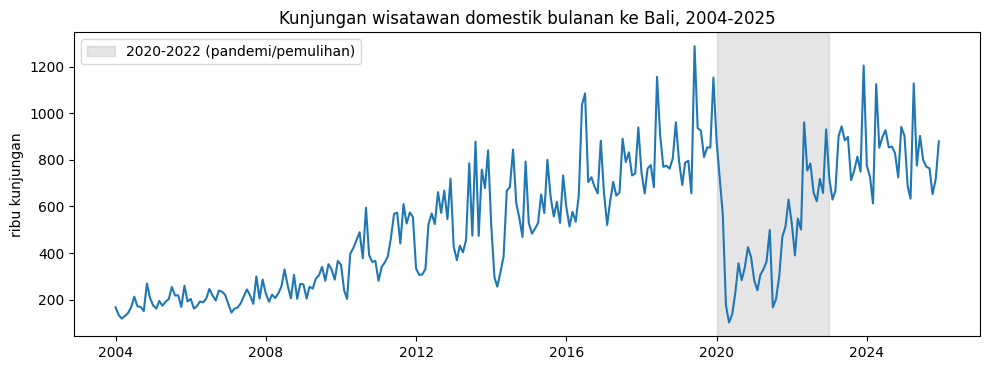

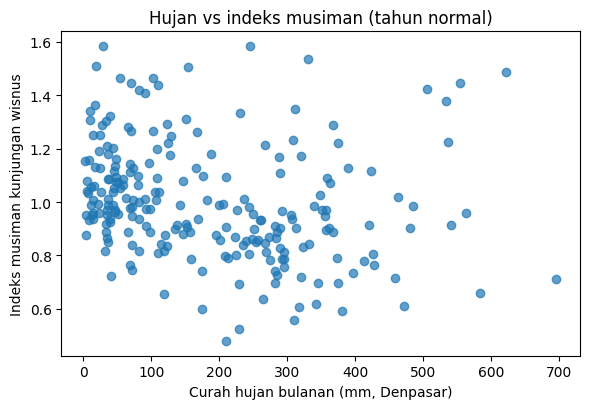

In [ ]:
# ===== SEL 27: Visualisasi untuk presentasi =====
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 3.8))
tgl = pd.to_datetime(dict(year=df_gabung.tahun, month=df_gabung.bulan, day=1))
ax.plot(tgl, df_gabung["kunjungan"] / 1000, color="#1f77b4")
ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2022-12-31"), color="grey", alpha=0.2, label="2020-2022 (pandemi/pemulihan)")
ax.set_title("Kunjungan wisatawan domestik bulanan ke Bali, 2004-2025")
ax.set_ylabel("ribu kunjungan"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "kunjungan_wisnus_bulanan.png", dpi=150); plt.show()

d = df_gabung[df_gabung.periode_normal]
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.scatter(d["curah_hujan_total_mm"], d["indeks_musiman"], alpha=0.7)
ax.set_xlabel("Curah hujan bulanan (mm, Denpasar)"); ax.set_ylabel("Indeks musiman kunjungan wisnus")
ax.set_title("Hujan vs indeks musiman (tahun normal)")
fig.tight_layout(); fig.savefig(FIG_DIR / "hujan_vs_indeks_musiman.png", dpi=150); plt.show()

In [ ]:
# ===== SEL 28: Simpan hasil gabungan + metadata =====
path_out = PROCESSED_DIR / "bali_wisnus_cuaca_bulanan.csv"
df_gabung.to_csv(path_out, index=False, encoding="utf-8-sig")
df_asosiasi.to_csv(PROCESSED_DIR / "asosiasi_spearman.csv", index=False, encoding="utf-8-sig")

kamus = {"tahun": "Tahun kalender", "bulan": "Bulan (1-12)",
         "kunjungan": "Jumlah kunjungan wisatawan domestik ke Bali (kunjungan, hasil survei Dinas Pariwisata Bali)",
         "suhu_rata2_c": "Rata-rata suhu harian 2 m (derajat C), Denpasar",
         "curah_hujan_total_mm": "Total curah hujan bulanan (mm), Denpasar",
         "hari_hujan": "Jumlah hari dengan hujan >= 1 mm",
         "angin_maks_kmh": "Kecepatan angin maksimum harian 10 m (km/jam) - maksimum bulanan",
         "hari_tercatat": "Jumlah hari berdata cuaca", "hari_seharusnya": "Jumlah hari dalam bulan",
         "periode": "Penanda periode (pra-pandemi/pandemi-pemulihan/pasca-pemulihan)",
         "periode_normal": "False untuk 2020-2022",
         "indeks_musiman": "Kunjungan bulan / rata-rata bulanan tahun yang sama"}
metadata = {
    "dibuat_utc": utc_now(), "file_hasil": path_out.name,
    "jumlah_baris": int(df_gabung.shape[0]), "jumlah_kolom": int(df_gabung.shape[1]),
    "kolom": kamus,
    "sumber": [{"berkas": CSV_WISNUS, "url": URL_CSV_SUMBER, "sumber_asli": "Hasil Survei Dinas Pariwisata Provinsi Bali"},
               {"berkas": NAMA_RAW_OM, "url": URL_OPENMETEO, "parameter": PARAMS_OM}],
    "metode_merge": "pd.merge(how='left', on=['tahun','bulan'], validate='one_to_one')",
    "bukti_merge": BUKTI_MERGE,
    "validasi_silang_antar_sumber": VALIDASI_SILANG,
    "md5_hasil": md5_file(path_out),
    "lisensi_sumber": "Needs verification (lihat docs/provenance.json); Open-Meteo CC BY 4.0 (verifikasi)",
    "catatan": "Analisis hanya asosiasi; cuaca satu titik (Denpasar); wisnus dari survei (bukan sensus); 2020-2022 terdistorsi pandemi.",
}
(PROCESSED_DIR / "metadata_hasil_gabungan.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps({k: metadata[k] for k in ["file_hasil", "jumlah_baris", "jumlah_kolom", "bukti_merge", "md5_hasil"]}, indent=2))

{
  "file_hasil": "bali_wisnus_cuaca_bulanan.csv",
  "jumlah_baris": 264,
  "jumlah_kolom": 12,
  "bukti_merge": {
    "baris_kiri": 264,
    "baris_kanan": 264,
    "baris_hasil": 264,
    "kunci_ganda": 0,
    "tanpa_pasangan": 0,
    "validate": "one_to_one"
  },
  "md5_hasil": "c46663cefa99a0ea8d0fdfcc55a78986"
}


## BAB 7. Penutup: verifikasi, checklist final, dan ringkasan presentasi

In [ ]:
# ===== SEL 29: Verifikasi MD5 semua berkas mentah (bukti raw tidak berubah) =====
tampil = []
for e in PROVENANCE:
    p = BASE_DIR / e["file_lokal"]
    sekarang = md5_file(p) if p.exists() else None
    tampil.append({"sumber": e["nama_sumber"], "metode": e["metode_akuisisi"],
                   "status": "OK" if sekarang == e["md5"] else "BERUBAH/HILANG"})
df_verif = pd.DataFrame(tampil)
display(df_verif)
assert (df_verif["status"] == "OK").all(), "Ada berkas mentah yang berubah atau hilang!"
print("Semua berkas mentah utuh (MD5 sama dengan catatan provenance).")

,sumber,metode,status
0,Table-1-7-Final-5.xls,download manual,OK
1,Table-17-Final-7.xlsx,download manual,OK
2,Table-24-31-Final-5.xls,download manual,OK
3,"Banyaknya Wisatawan Domestik Bulanan ke Bali, 2004-2025.csv",download manual,OK
4,"Banyaknya Wisatawan Mancanegara ke Bali dan Indonesia, 1969-2025.csv",download manual,OK
5,"Jumlah Wisatawan Mancanegara Bulanan ke Bali Menurut Pintu Masuk, 2025.csv",download manual,OK
6,"Tingkat Penghunian Kamar (TPK) Hotel Bintang Menurut Kelas di Provinsi Bali, 2025.csv",download manual,OK
7,_Banyaknya Wisatawan Mancanegara yang Datang Langsung ke Bali Menurut Kebangsaan 2019-2024.csv,download manual,OK
8,bukti_disparda_halaman_publikasi.html,web (bukti kepatuhan),OK
9,bukti_openmeteo_lisensi.html,web (bukti kepatuhan),OK


Semua berkas mentah utuh (MD5 sama dengan catatan provenance).


In [ ]:
# ===== SEL 30: Perbarui Data Ethics Checklist (kini robots.txt & scraping sudah ada buktinya) =====
display(bangun_checklist())

,no,butir,status,bukti
0,1,Sumber data dan URL dicantumkan,Selesai,"8/8 berkas mentah tercatat di docs/provenance.json (URL, waktu UTC, lisensi, MD5)."
1,2,Lisensi data diperiksa dan didokumentasikan,Sebagian,"Status: Needs verification. Bukti halaman: data/raw/bukti_kepatuhan, ringkasan: docs/bukti_lisensi_tos.csv."
2,3,robots.txt dan Terms of Service diperiksa,Sebagian,robots.txt diperiksa (docs/bukti_robots.csv). ToS BELUM dibaca manual (set TOS_DIBACA_MANUAL=True setelah dibaca).
3,4,PII diidentifikasi,Selesai,"Pemindaian seluruh sheet Excel dan seluruh CSV (docs/pii_scan_semua_sheet.csv): email, telepon, dan kata header PII."
4,5,PII dihapus/disamarkan/dinyatakan tidak relevan,Selesai,"Dataset utama (wisnus bulanan) hanya angka agregat (tahun, bulan, jumlah). Berkas lain juga agregat statistik; tidak..."
5,6,Data minimization diterapkan,Selesai,"Hanya 5 CSV statistik + Tabel 6, 7, 17, 28 yang dibaca/diproses; sheet Excel lain tidak diproses; dari API cuaca han..."
6,7,Potensi bias sampel dianalisis,Draf (tinjau ulang),"Wisnus berasal dari survei Dinas Pariwisata (estimasi survei, bukan sensus) sehingga ada galat sampling; wisman hany..."
7,8,Tujuan penggunaan data dijelaskan,Draf (tinjau ulang),"Tujuan akademik (UTS DAM): latihan akuisisi dan integrasi data; hasil hanya menyimpulkan asosiasi, bukan sebab-akiba..."
8,9,Rencana penyimpanan dan penghapusan data dibuat,Draf (perlu konfirmasi),Disimpan di Google Drive pribadi mahasiswa; raw tidak diubah; salinan dihapus setelah nilai mata kuliah final (jadwa...


In [ ]:
# ===== SEL 31: Ringkasan alur akuisisi untuk demo/presentasi + isi folder =====
print("RINGKASAN")
print(f"- Berkas      : 5 CSV + Tabel 6, 7, 17, 28 -> dataset utama wisnus bulanan {df_wisnus.shape[0]} observasi "
      f"({int(df_wisnus.tahun.min())}-{int(df_wisnus.tahun.max())}); valid vs total BALI & growth; "
      f"validasi silang antar-sumber {'SAMA' if VALIDASI_SILANG['semua_sama'] else 'ADA PERBEDAAN'} ({VALIDASI_SILANG['tahun_diuji']} tahun)")
print(f"- API         : Open-Meteo -> {len(df_cuaca)} baris harian -> {len(df_cuaca_bulanan)} baris bulanan")
print(f"- Scraping    : Disparda daya tarik wisata -> {len(df_scrape)} listing (robots.txt diperiksa)")
print(f"- Merge       : {BUKTI_MERGE['baris_kiri']} x {BUKTI_MERGE['baris_kanan']} -> {BUKTI_MERGE['baris_hasil']} baris, validate=one_to_one, tanpa duplikasi")
print(f"- Provenance  : {len(PROVENANCE)} sumber tercatat\n")
print("Isi folder proyek:")
for p in sorted(BASE_DIR.rglob("*")):
    if p.is_file() and ".ipynb_checkpoints" not in str(p):
        print(" ", p.relative_to(BASE_DIR))

RINGKASAN
- Berkas      : 5 CSV + Tabel 6, 7, 17, 28 -> dataset utama wisnus bulanan 264 observasi (2004-2025); valid vs total BALI & growth; validasi silang antar-sumber SAMA (7 tahun)
- API         : Open-Meteo -> 8036 baris harian -> 264 baris bulanan
- Scraping    : Disparda daya tarik wisata -> 50 listing (robots.txt diperiksa)
- Merge       : 264 x 264 -> 264 baris, validate=one_to_one, tanpa duplikasi
- Provenance  : 21 sumber tercatat

Isi folder proyek:
  data/interim/audit_seluruh_csv.csv
  data/interim/audit_seluruh_sheet.csv
  data/interim/cuaca_bulanan.csv
  data/interim/cuaca_harian.csv
  data/interim/scrape_daya_tarik_wisata.csv
  data/processed/asosiasi_spearman.csv
  data/processed/bali_wisnus_cuaca_bulanan.csv
  data/processed/metadata_hasil_gabungan.json
  data/processed/tabel_17_bersih.csv
  data/processed/tabel_28_bersih.csv
  data/processed/tabel_6_bersih.csv
  data/processed/tabel_7_bersih.csv
  data/processed/tpk_hotel_bintang_2025.csv
  data/processed/validasi_

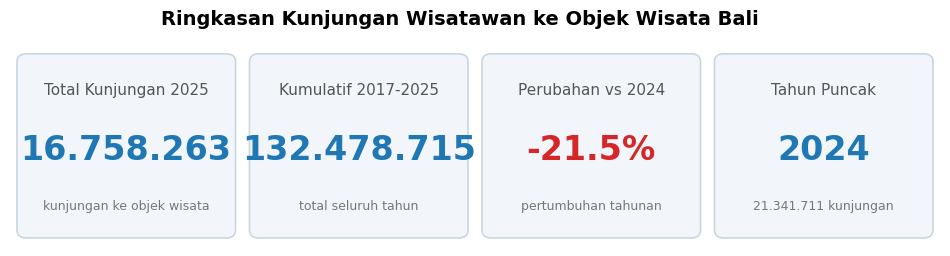

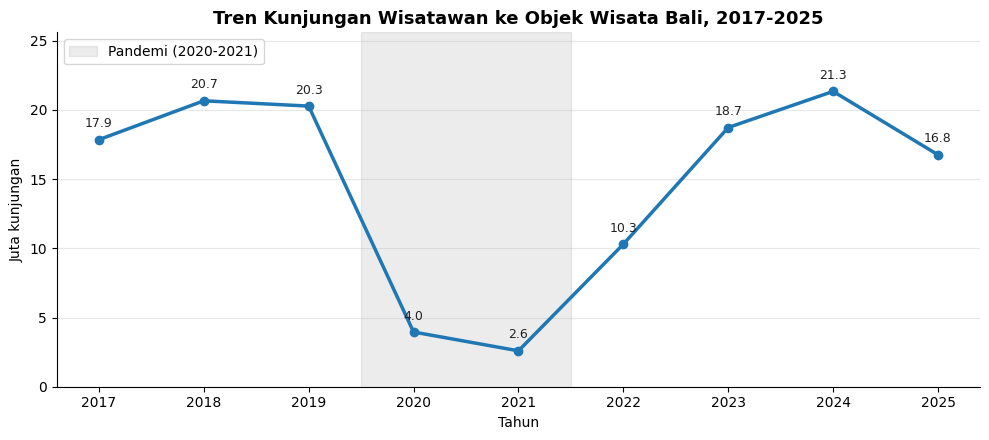

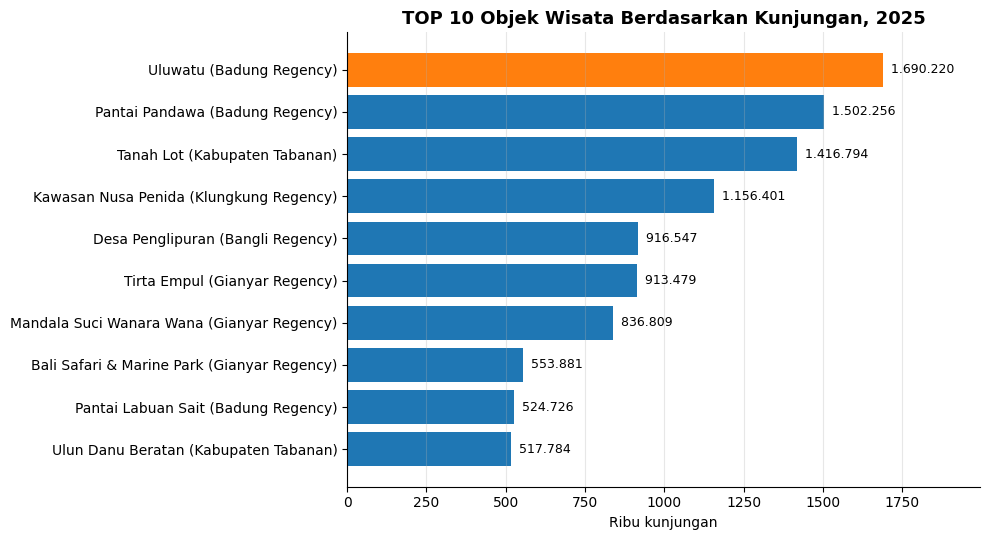

Peringkat objek wisata 2025 (200 objek) - disimpan di data/processed.


Peringkat,Objek Wisata,Kabupaten/Kota,Kunjungan 2025,Pangsa (%)
1,Uluwatu,Badung Regency,1.690.220,10.09
2,Pantai Pandawa,Badung Regency,1.502.256,8.96
3,Tanah Lot,Kabupaten Tabanan,1.416.794,8.45
4,Kawasan Nusa Penida,Klungkung Regency,1.156.401,6.90
5,Desa Penglipuran,Bangli Regency,916.547,5.47
6,Tirta Empul,Gianyar Regency,913.479,5.45
7,Mandala Suci Wanara Wana,Gianyar Regency,836.809,4.99
8,Bali Safari & Marine Park,Gianyar Regency,553.881,3.31
9,Pantai Labuan Sait,Badung Regency,524.726,3.13
10,Ulun Danu Beratan,Kabupaten Tabanan,517.784,3.09


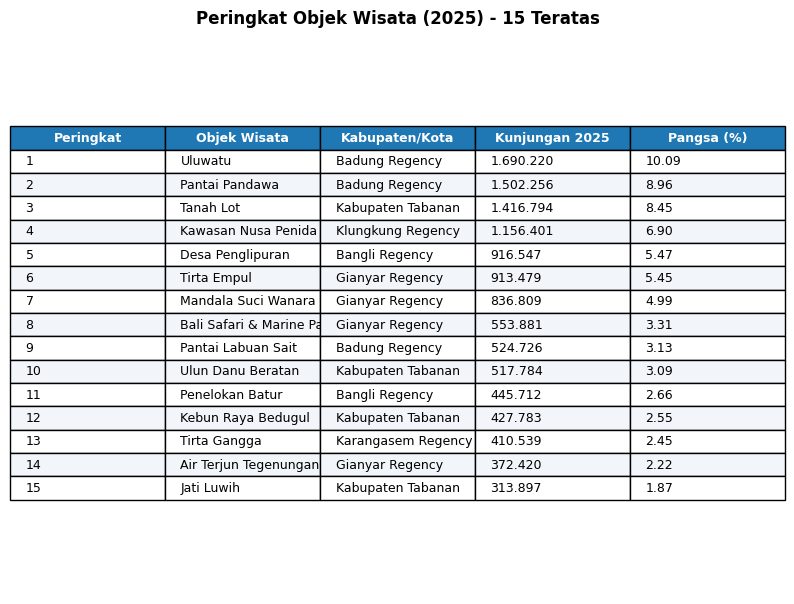

Gambar tersimpan di: /content/drive/MyDrive/UTS_DATAAKUISISI_pariwisata_2501010376/docs/gambar


In [ ]:
# ===== SEL 32: Visualisasi kunjungan objek wisata (KPI, tren, Top 10, tabel peringkat) =====
# Sumber: Tabel 17 (ODTW per kabupaten/kota) hasil parse_tabel_17 di SEL TAMBAHAN B.
# Letakkan sel ini SETELAH SEL TAMBAHAN C (atau setelah SEL 13), lalu jalankan.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# --- Pengaturan (ubah bila perlu) ---
TAHUN_AWAL, TAHUN_AKHIR = 2017, 2025
TAHUN_TOP = 2025          # tahun yang dipakai untuk Top 10 dan tabel peringkat
TOP_N = 10
WARNA = {"utama": "#1f77b4", "aksen": "#ff7f0e", "teks": "#222222", "kartu": "#f2f6fa"}

def fmt(x):
    # Format angka gaya Indonesia: 1.234.567
    return f"{x:,.0f}".replace(",", ".")

# --- 1) Ambil Tabel 17 (dari memori notebook; cadangan: CSV hasil simpan) ---
try:
    t17 = tabel_terpilih_bersih["17"].copy()
except (NameError, KeyError):
    t17 = pd.read_csv(PROCESSED_DIR / "tabel_17_bersih.csv")

# --- 2) Hitung total per tahun ---
# Kolom bertipe '2019_wisnus' / '2019_wisman' (2016-2017: '_total'). Total tahun = jumlah semua kolom tahun itu.
def total_tahun(d, tahun):
    kolom = [c for c in d.columns if re.match(rf"^{tahun}_", str(c))]
    if not kolom:
        return pd.Series(np.nan, index=d.index)
    return d[kolom].apply(pd.to_numeric, errors="coerce").sum(axis=1, min_count=1)

daftar_tahun = list(range(TAHUN_AWAL, TAHUN_AKHIR + 1))
for t in daftar_tahun:
    t17[f"total_{t}"] = total_tahun(t17, t)

# --- 3) Total kunjungan seluruh Bali per tahun (baris TOTAL di sumber) ---
baris_total = t17[t17["jenis_baris"] == "total_bali"]
if baris_total.empty:      # cadangan: jumlahkan subtotal kabupaten/kota
    tren = pd.Series({t: t17[t17.jenis_baris == "subtotal_kabupaten"][f"total_{t}"].sum() for t in daftar_tahun})
else:
    tren = pd.Series({t: baris_total[f"total_{t}"].iloc[0] for t in daftar_tahun})
tren = tren.dropna()
assert len(tren) > 0, "Tidak ada data total per tahun - periksa kolom tahun di Tabel 17."

# =====================================================================
# VISUAL 1: KPI Card - total kunjungan wisatawan
# =====================================================================
tahun_terakhir = int(tren.index.max())
nilai_akhir = tren.loc[tahun_terakhir]
tahun_sebelum = tahun_terakhir - 1
perubahan = ((nilai_akhir / tren.loc[tahun_sebelum] - 1) * 100) if tahun_sebelum in tren.index else np.nan
tahun_puncak = int(tren.idxmax())

kartu = [
    (f"Total Kunjungan {tahun_terakhir}", fmt(nilai_akhir), "kunjungan ke objek wisata"),
    (f"Kumulatif {int(tren.index.min())}-{tahun_terakhir}", fmt(tren.sum()), "total seluruh tahun"),
    (f"Perubahan vs {tahun_sebelum}", f"{perubahan:+.1f}%" if not np.isnan(perubahan) else "n/a", "pertumbuhan tahunan"),
    ("Tahun Puncak", str(tahun_puncak), f"{fmt(tren.max())} kunjungan"),
]
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.set_xlim(0, len(kartu)); ax.set_ylim(0, 1); ax.axis("off")
for i, (judul, nilai, ket) in enumerate(kartu):
    ax.add_patch(FancyBboxPatch((i + 0.04, 0.05), 0.92, 0.9, boxstyle="round,pad=0.01,rounding_size=0.04",
                                fc=WARNA["kartu"], ec="#c9d6e2", lw=1.2))
    ax.text(i + 0.5, 0.78, judul, ha="center", va="center", fontsize=11, color="#555555")
    warna_nilai = WARNA["utama"]
    if judul.startswith("Perubahan") and not np.isnan(perubahan):
        warna_nilai = "#2ca02c" if perubahan >= 0 else "#d62728"
    ax.text(i + 0.5, 0.48, nilai, ha="center", va="center", fontsize=24, fontweight="bold", color=warna_nilai)
    ax.text(i + 0.5, 0.2, ket, ha="center", va="center", fontsize=9, color="#777777")
fig.suptitle("Ringkasan Kunjungan Wisatawan ke Objek Wisata Bali", fontsize=14, fontweight="bold", y=1.02)
fig.savefig(FIG_DIR / "kpi_total_kunjungan.png", dpi=150, bbox_inches="tight")
plt.show()

# =====================================================================
# VISUAL 2: Line Chart - tren kunjungan 2017-2025
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(tren.index, tren.values / 1e6, marker="o", lw=2.5, color=WARNA["utama"])
for t, v in tren.items():
    ax.annotate(f"{v/1e6:.1f}", (t, v / 1e6), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=9, color=WARNA["teks"])
if tren.index.min() <= 2021 and tren.index.max() >= 2020:
    ax.axvspan(2019.5, 2021.5, color="grey", alpha=0.15, label="Pandemi (2020-2021)")
    ax.legend(loc="upper left")
ax.set_xticks(list(tren.index))
ax.set_title(f"Tren Kunjungan Wisatawan ke Objek Wisata Bali, {int(tren.index.min())}-{tahun_terakhir}",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Tahun"); ax.set_ylabel("Juta kunjungan")
ax.set_ylim(0, tren.max() / 1e6 * 1.2)
ax.grid(axis="y", alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "tren_kunjungan_2017_2025.png", dpi=150)
plt.show()

# =====================================================================
# VISUAL 3 & 4: Top 10 (Horizontal Bar) dan Tabel Peringkat
# =====================================================================
kol_top = f"total_{TAHUN_TOP}"
objek = t17[t17["jenis_baris"] == "objek"].copy()
objek = objek[objek[kol_top].notna() & (objek[kol_top] > 0)]
objek = objek.sort_values(kol_top, ascending=False).reset_index(drop=True)
total_objek = objek[kol_top].sum()

df_rank = pd.DataFrame({
    "Peringkat": np.arange(1, len(objek) + 1),
    "Objek Wisata": objek["objek_wisata"],
    "Kabupaten/Kota": objek["kabupaten_kota"].astype(str).str.title(),
    f"Kunjungan {TAHUN_TOP}": objek[kol_top].astype(int),
    "Pangsa (%)": (objek[kol_top] / total_objek * 100).round(2),
})
df_rank.to_csv(PROCESSED_DIR / f"peringkat_objek_wisata_{TAHUN_TOP}.csv", index=False, encoding="utf-8-sig")

# --- Top 10: horizontal bar chart ---
top = df_rank.head(TOP_N).iloc[::-1]          # dibalik agar peringkat 1 tampil paling atas
label = [f"{o} ({k})" for o, k in zip(top["Objek Wisata"], top["Kabupaten/Kota"])]
fig, ax = plt.subplots(figsize=(10, 5.5))
warna_bar = [WARNA["aksen"] if p == 1 else WARNA["utama"] for p in top["Peringkat"]]
batang = ax.barh(label, top[f"Kunjungan {TAHUN_TOP}"] / 1e3, color=warna_bar)
for b, v in zip(batang, top[f"Kunjungan {TAHUN_TOP}"]):
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f"  {fmt(v)}", va="center", fontsize=9)
ax.set_title(f"TOP {TOP_N} Objek Wisata Berdasarkan Kunjungan, {TAHUN_TOP}", fontsize=13, fontweight="bold")
ax.set_xlabel("Ribu kunjungan")
ax.set_xlim(0, top[f"Kunjungan {TAHUN_TOP}"].max() / 1e3 * 1.18)
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / f"top{TOP_N}_objek_wisata_{TAHUN_TOP}.png", dpi=150)
plt.show()

# --- Tabel peringkat (ditampilkan interaktif + disimpan sebagai gambar) ---
print(f"Peringkat objek wisata {TAHUN_TOP} ({len(df_rank)} objek) - disimpan di data/processed.")
try:
    tampil = (df_rank.head(20).style
              .format({f"Kunjungan {TAHUN_TOP}": fmt, "Pangsa (%)": "{:.2f}"})
              .bar(subset=[f"Kunjungan {TAHUN_TOP}"], color="#9ecae1")
              .hide(axis="index"))
    display(tampil)
except Exception:
    display(df_rank.head(20))

n_tabel = min(15, len(df_rank))
fig, ax = plt.subplots(figsize=(10, 0.42 * n_tabel + 1))
ax.axis("off")
sel = df_rank.head(n_tabel).copy()
sel[f"Kunjungan {TAHUN_TOP}"] = sel[f"Kunjungan {TAHUN_TOP}"].map(fmt)
sel["Pangsa (%)"] = sel["Pangsa (%)"].map(lambda x: f"{x:.2f}")
tabel = ax.table(cellText=sel.values, colLabels=sel.columns, loc="center", cellLoc="left")
tabel.auto_set_font_size(False); tabel.set_fontsize(9); tabel.scale(1, 1.4)
for (r, c), cell in tabel.get_celld().items():
    if r == 0:
        cell.set_facecolor(WARNA["utama"]); cell.set_text_props(color="white", fontweight="bold")
    elif r % 2 == 0:
        cell.set_facecolor("#f2f6fa")
ax.set_title(f"Peringkat Objek Wisata ({TAHUN_TOP}) - {n_tabel} Teratas", fontsize=12, fontweight="bold")
fig.savefig(FIG_DIR / f"tabel_peringkat_objek_wisata_{TAHUN_TOP}.png", dpi=150, bbox_inches="tight")
plt.show()
print("Gambar tersimpan di:", FIG_DIR)

## Sebelum dikumpulkan
1. **Runtime > Run all** sampai semua sel selesai tanpa error.
2. Isi `EMAIL_KAMPUS` dan `URL_CSV_SUMBER` (SEL 2), serta `HASIL_CEK_LISENSI`, `TOS_DIBACA_MANUAL`, `RENCANA_DIKONFIRMASI` (SEL 17), lalu jalankan ulang SEL 17 dan SEL 30.
3. Upload notebook + `data/raw` + `data/processed` + `docs/` ke GitHub/Colab, bagikan URL ke ELSA.